# NB5b — FOOOF decomposition

แยกสเปกตรัมออกเป็นส่วนที่เป็นจังหวะ (ยอดคลื่น) กับส่วนพื้นหลัง 1/f เพื่อตอบว่า
การเปลี่ยนแปลงหลังทำงานเกิดที่ส่วนไหน

**ผลที่ใช้จริงคือ v4 เท่านั้น** (เซลล์ 10–12) ไฟล์ผลลัพธ์คือ
`outputs/fooof_features_v4.csv` ซึ่ง NB5c และ NB6 อ่านต่อ

เวอร์ชันก่อนหน้าถูกเก็บไว้โดยตั้งใจ เพราะความต่างระหว่างเวอร์ชันคือหลักฐานของ
ข้อค้นพบเชิงวิธีวิทยาข้อหนึ่งของงานนี้ ว่าการตั้งค่าเปลี่ยนข้อสรุปได้มากแค่ไหน

| เวอร์ชัน | บริเวณ | filter | ช่วง fit | Welch | ICA | สถานะ |
|---|---|---|---|---|---|---|
| v2 | ท้ายทอย | 1–40 | 1–40 | 2 วิ | ตา | ถูกแทนที่ |
| regions | 3 บริเวณ | 1–40 | 1–40 | 2 วิ | ตา | ถูกแทนที่ |
| v3 | 3 บริเวณ | 0.5–45 | 1–30 | 6 วิ | ตา + กล้ามเนื้อ (0.5) | ถูกแทนที่ |
| **v4** | 3 บริเวณ | 0.5–45 | 1–30 | 6 วิ | ตา + กล้ามเนื้อ (0.9) | **ใช้จริง** |

เซลล์สกัดทุกตัวอ่าน cache ของตัวเองได้ การกด Restart & Run All จึงเร็ว
แต่ถ้าเริ่มจากศูนย์จะใช้เวลารวมหลายชั่วโมง

In [1]:
# ── Cell 1: Imports ───────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import glob
import os
import mne
from specparam import SpectralModel
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

os.makedirs('outputs', exist_ok=True)
print("Libraries loaded")

Libraries loaded


## v2 — เวอร์ชันแรก (ถูกแทนที่แล้ว)

ท้ายทอยอย่างเดียว fit 1–40 Hz บนข้อมูลที่กรองไว้ที่ 40 Hz ซึ่งเป็นการ fit ชนขอบ
ตัวกรองของตัวเอง ทำให้ FOOOF เห็นความชันเทียมและประมาณ exponent สูงเกินจริง

ผลที่ได้จากเวอร์ชันนี้ โดยเฉพาะข้อสรุปว่า exponent ไม่เปลี่ยนหลังทำงาน
**ไม่ถูกต้อง** และถูกแก้ใน v3 เก็บไว้เพื่อแสดงขนาดของผลกระทบ

In [2]:
# ── Cell 2: หา EDF files และ occipital channels ───────────────────────────────
edf_files = sorted(glob.glob('Dataset/sub-*/ses-1/eeg/*_eeg.edf'))
occ_chs   = ['O1', 'Oz', 'O2', 'PO3', 'POz', 'PO4']

print(f"Total EDF files: {len(edf_files)}")
print("Example:", edf_files[0])

Total EDF files: 2432
Example: Dataset/sub-001/ses-1/eeg/sub-001_ses-1_task-EyesClosed_acq-post_eeg.edf


In [3]:
# Cell 3 — preprocessing + FOOOF (real ICA, quality tracking, resumable)
import mne, numpy as np, pandas as pd, glob, os, warnings
from mne.time_frequency import psd_array_welch
from specparam import SpectralModel
warnings.filterwarnings('ignore')
mne.set_log_level('ERROR')

os.makedirs('outputs', exist_ok=True)
OUT       = 'outputs/fooof_features_v2.csv'
occ_chs   = ['O1', 'Oz', 'O2', 'PO3', 'POz', 'PO4']
eog_proxy = ['Fp1', 'Fp2']          # ใช้แทน EOG channel

edf_files = sorted(glob.glob('Dataset/sub-*/ses-1/eeg/*_eeg.edf'))
print(f"Total files: {len(edf_files)}")

# ── resume ──
done, records = set(), []
if os.path.exists(OUT):
    _prev = pd.read_csv(OUT)
    if {'file', 'n_eog_excluded'} <= set(_prev.columns):
        done, records = set(_prev['file']), _prev.to_dict('records')
        print(f"Resuming — {len(done)} files already done")
    else:
        print("Old-format cache found — starting fresh")

# ── helper: band power 3 นิยาม ──
def corrected_band(freqs, power, offset, exponent, lo, hi):
    """log10 power ส่วนที่สูงกว่าเส้น 1/f, เฉลี่ยในช่วง [lo,hi)"""
    m  = (freqs >= lo) & (freqs < hi)
    ap = offset - exponent * np.log10(freqs[m])
    return (np.log10(power[m]) - ap).mean()

def relative_band(freqs, power, lo, hi):
    """relative power แบบเดิม ไม่แก้ 1/f"""
    m  = (freqs >= lo) & (freqs < hi)
    mt = (freqs >= 1)  & (freqs < 40)
    return power[m].sum() / power[mt].sum()

def corrected_relative(freqs, power, offset, exponent, lo, hi):
    """สัดส่วนของ residual power (ใกล้เคียงนิยามที่ Yang น่าจะใช้กับ beta GLMM)"""
    mt    = (freqs >= 1) & (freqs < 40)
    resid = np.clip(power[mt] - 10 ** (offset - exponent * np.log10(freqs[mt])), 0, None)
    band  = (freqs[mt] >= lo) & (freqs[mt] < hi)
    tot   = resid.sum()
    return resid[band].sum() / tot if tot > 0 else np.nan

# ── main loop ──
n_err = 0
for i, fpath in enumerate(edf_files):
    fname = os.path.basename(fpath)
    if fname in done:
        continue

    parts = fname.replace('_eeg.edf', '').split('_')
    subj, task, acq = parts[0], parts[2].replace('task-', ''), parts[3].replace('acq-', '')

    try:
        raw = mne.io.read_raw_edf(fpath, preload=True, verbose=False)

        # 1. resample → 250 Hz
        if raw.info['sfreq'] != 250:
            raw.resample(250, verbose=False)

        # 2. bandpass 1–40 + notch 50
        raw.filter(1., 40., verbose=False)
        raw.notch_filter(50., verbose=False)

        # 3. ICA — ลบ component ที่สัมพันธ์กับการกะพริบตา (ต้องตั้ง exclude!)
        n_eog = 0
        try:
            n_comp = min(20, len(mne.pick_types(raw.info, eeg=True)) - 1)
            ica = mne.preprocessing.ICA(n_components=n_comp, random_state=42,
                                        max_iter='auto', verbose=False)
            ica.fit(raw, decim=3, verbose=False)
            eog_ch = [c for c in eog_proxy if c in raw.ch_names]
            if eog_ch:
                eog_idx, _ = ica.find_bads_eog(raw, ch_name=eog_ch, verbose=False)
                ica.exclude = eog_idx
                n_eog = len(eog_idx)
                ica.apply(raw, verbose=False)      # apply in-place หลังตั้ง exclude
        except Exception:
            n_eog = -1                              # ICA ล้มเหลว บันทึกไว้

        # 4. average reference
        raw.set_eeg_reference('average', projection=False, verbose=False)

        # 5. ตัดช่วงที่เกิน ±100 µV (คิดบน channel ที่ใช้วิเคราะห์)
        picks = [ch for ch in occ_chs if ch in raw.ch_names]
        if not picks:
            continue
        data      = raw.get_data(picks=picks)
        good_mask = np.all(np.abs(data) < 100e-6, axis=0)
        good_frac = good_mask.mean()
        if good_mask.sum() < raw.info['sfreq'] * 10:   # เหลือสัญญาณ < 10 วินาที
            continue

        # 6. PSD (Welch) เฉพาะช่วงที่สะอาด
        sfreq = raw.info['sfreq']
        psds, freqs = psd_array_welch(
            data[:, good_mask], sfreq=sfreq, fmin=1, fmax=40,
            n_fft=int(sfreq * 2), n_overlap=int(sfreq), verbose=False)
        power = psds.mean(axis=0)

        # 7. FOOOF
        fm = SpectralModel(peak_width_limits=[1, 8], min_peak_height=0.03,
                           aperiodic_mode='fixed', verbose=False)
        fm.fit(freqs, power, freq_range=[1, 40])
        offset, exponent = fm.get_params('aperiodic')

        records.append({
            'file': fname, 'subject': subj, 'task': task, 'condition': acq,
            'ap_offset': offset, 'ap_exponent': exponent,
            'low_alpha_corr':     corrected_band(freqs, power, offset, exponent, 8, 10),
            'high_alpha_corr':    corrected_band(freqs, power, offset, exponent, 10, 13),
            'low_alpha_rel':      relative_band(freqs, power, 8, 10),
            'high_alpha_rel':     relative_band(freqs, power, 10, 13),
            'low_alpha_corr_rel': corrected_relative(freqs, power, offset, exponent, 8, 10),
            'high_alpha_corr_rel':corrected_relative(freqs, power, offset, exponent, 10, 13),
            'n_eog_excluded': n_eog, 'good_frac': good_frac, 'n_chan_occ': len(picks),
        })

    except Exception:
        n_err += 1

    # flush ทุก 100 ไฟล์ — รันค้างแล้วรันต่อได้
    if (i + 1) % 100 == 0:
        pd.DataFrame(records).to_csv(OUT, index=False)
        print(f"  {i+1}/{len(edf_files)} — {len(records)} records, {n_err} errors")

df_fooof = pd.DataFrame(records)
df_fooof.to_csv(OUT, index=False)
print(f"\nDone: {len(df_fooof)} records, {n_err} errors → {OUT}")
print(f"ICA: median {df_fooof['n_eog_excluded'].median():.0f} comp excluded, "
      f"{(df_fooof['n_eog_excluded'] == -1).sum()} files ICA failed")
print(f"Clean signal retained: {df_fooof['good_frac'].mean()*100:.1f}% (mean)")
print(f"Failed FOOOF fits (exponent <= 0): {(df_fooof['ap_exponent'] <= 0).sum()}")

Total files: 2432
Resuming — 2432 files already done

Done: 2432 records, 0 errors → outputs/fooof_features_v2.csv
ICA: median 2 comp excluded, 0 files ICA failed
Clean signal retained: 99.9% (mean)
Failed FOOOF fits (exponent <= 0): 6


## regions — ขยายเป็น 3 บริเวณ (ถูกแทนที่แล้ว)

ยังใช้ค่าตั้งเดิมของ v2 เปลี่ยนแค่การเพิ่ม frontal และ central
ไฟล์ผลลัพธ์ `fooof_features_regions.csv` ไม่มี notebook ใดใช้ต่อ

In [4]:
# Cell 4 — quality filter + within-group Wilcoxon + between-group Mann-Whitney
from scipy.stats import wilcoxon, mannwhitneyu

df_fooof = pd.read_csv('outputs/fooof_features_v2.csv')

# ── quality filter: exponent <= 0 เป็นไปไม่ได้ทางสรีรวิทยา = fit ล้มเหลว ──
n_before = len(df_fooof)
df_fooof = df_fooof[df_fooof['ap_exponent'] > 0].copy()
print(f"Quality filter: dropped {n_before - len(df_fooof)} rows "
      f"with ap_exponent <= 0 ({len(df_fooof)} remain)")
participants = pd.read_csv('Dataset/participants.tsv', sep='\t')
ages = participants.set_index('participant_id')['age']

pre  = df_fooof[df_fooof['condition'] == 'pre' ].set_index(['subject','task'])
post = df_fooof[df_fooof['condition'] == 'post'].set_index(['subject','task'])
merged = pre.join(post, lsuffix='_pre', rsuffix='_post', how='inner').reset_index()

merged['age']   = merged['subject'].map(ages)
merged['group'] = merged['age'].apply(
    lambda a: 'Young' if a <= 34 else ('Older' if a >= 51 else 'Middle'))

ec = merged[(merged['task'] == 'EyesClosed') & (merged['group'] != 'Middle')].copy()
print(f"EC pairs — Young: {(ec['group']=='Young').sum()}, Older: {(ec['group']=='Older').sum()}")

measures = ['low_alpha_corr', 'high_alpha_corr', 'ap_exponent', 'ap_offset',
            'low_alpha_rel',  'high_alpha_rel',
            'low_alpha_corr_rel', 'high_alpha_corr_rel']

# ── A) within-group: post vs pre ──
rows = []
for g, d in ec.groupby('group'):
    for m in measures:
        a, b = d[f'{m}_pre'].values, d[f'{m}_post'].values
        ok = ~(np.isnan(a) | np.isnan(b))
        if ok.sum() < 5:
            continue
        _, p = wilcoxon(b[ok], a[ok])
        rows.append({'group': g, 'measure': m, 'n': int(ok.sum()),
                     'median_pre':  np.median(a[ok]),
                     'median_post': np.median(b[ok]),
                     'median_change': np.median(b[ok] - a[ok]),
                     'pct_increase': ((b[ok] - a[ok]) > 0).mean() * 100,
                     'p': p})
res = pd.DataFrame(rows)
res['p_bonf'] = (res['p'] * len(res)).clip(upper=1)
print("\n=== Within-group: post vs pre (EC, occipital) ===")
print(res.round(4).to_string(index=False))
res.to_csv('outputs/fooof_wilcoxon_ec.csv', index=False)

# ── B) between-group: Young vs Older ที่ baseline (pre) ──
rows_bg = []
for m in measures:
    yv = ec[ec['group'] == 'Young'][f'{m}_pre'].dropna()
    ov = ec[ec['group'] == 'Older'][f'{m}_pre'].dropna()
    if len(yv) < 5 or len(ov) < 5:
        continue
    u, p = mannwhitneyu(yv, ov)
    rows_bg.append({'measure': m, 'n_young': len(yv), 'n_older': len(ov),
                    'median_young': yv.median(), 'median_older': ov.median(),
                    'p': p})
res_bg = pd.DataFrame(rows_bg)
res_bg['p_bonf'] = (res_bg['p'] * len(res_bg)).clip(upper=1)
print("\n=== Between-group at baseline: Young vs Older (EC, pre) ===")
print(res_bg.round(5).to_string(index=False))
res_bg.to_csv('outputs/fooof_mannwhitney_age.csv', index=False)

Quality filter: dropped 6 rows with ap_exponent <= 0 (2426 remain)
EC pairs — Young: 203, Older: 228

=== Within-group: post vs pre (EC, occipital) ===
group             measure   n  median_pre  median_post  median_change  pct_increase      p  p_bonf
Older      low_alpha_corr 228      0.8236       0.9025         0.0819       69.2982 0.0000  0.0000
Older     high_alpha_corr 228      0.7388       0.6868        -0.0251       42.5439 0.0337  0.5398
Older         ap_exponent 228      1.0660       1.0683        -0.0379       42.5439 0.0252  0.4030
Older           ap_offset 228    -11.4232     -11.3950         0.0066       52.6316 0.5682  1.0000
Older       low_alpha_rel 228      0.1581       0.2118         0.0217       67.5439 0.0000  0.0000
Older      high_alpha_rel 228      0.1749       0.1607        -0.0107       39.4737 0.0003  0.0047
Older  low_alpha_corr_rel 228      0.2355       0.3289         0.0316       66.6667 0.0000  0.0000
Older high_alpha_corr_rel 228      0.2682       0.2504  

In [5]:
# Cell 5 — 3-region FOOOF (frontal / central / occipital), resumable
import mne, numpy as np, pandas as pd, glob, os, warnings
from mne.time_frequency import psd_array_welch
from specparam import SpectralModel
warnings.filterwarnings('ignore')
mne.set_log_level('ERROR')

OUT_R     = 'outputs/fooof_features_regions.csv'
eog_proxy = ['Fp1', 'Fp2']

# ไม่ใส่ Fp1/Fp2 ใน frontal เพราะใช้เป็น EOG proxy — เลี่ยง residual ocular
REGIONS = {
    'frontal':   ['F3', 'Fz', 'F4', 'F7', 'F8', 'AF3', 'AF4'],
    'central':   ['C3', 'Cz', 'C4', 'FC1', 'FC2', 'CP1', 'CP2'],
    'occipital': ['O1', 'Oz', 'O2', 'PO3', 'POz', 'PO4'],
}

edf_files = sorted(glob.glob('Dataset/sub-*/ses-1/eeg/*_eeg.edf'))

# ── ตรวจก่อนว่าแต่ละบริเวณมี channel ไหนอยู่จริง ──
_probe = mne.io.read_raw_edf(edf_files[0], preload=False, verbose=False)
print("Channels available per region:")
for rg, chs in REGIONS.items():
    found   = [c for c in chs if c in _probe.ch_names]
    missing = [c for c in chs if c not in _probe.ch_names]
    print(f"  {rg:10s} found {len(found)}/{len(chs)}: {found}"
          + (f"   missing: {missing}" if missing else ""))

# ── resume ──
done, records = set(), []
if os.path.exists(OUT_R):
    _prev = pd.read_csv(OUT_R)
    if {'file', 'region', 'n_eog_excluded'} <= set(_prev.columns):
        done, records = set(_prev['file']), _prev.to_dict('records')
        print(f"\nResuming — {len(done)} files already done")
    else:
        print("\nOld-format cache found — starting fresh")

# ── helpers (เหมือน Cell 3 แต่รับ freqs/power เป็น argument) ──
def corrected_band(freqs, power, offset, exponent, lo, hi):
    m  = (freqs >= lo) & (freqs < hi)
    ap = offset - exponent * np.log10(freqs[m])
    return (np.log10(power[m]) - ap).mean()

def relative_band(freqs, power, lo, hi):
    m  = (freqs >= lo) & (freqs < hi)
    mt = (freqs >= 1)  & (freqs < 40)
    return power[m].sum() / power[mt].sum()

def corrected_relative(freqs, power, offset, exponent, lo, hi):
    mt    = (freqs >= 1) & (freqs < 40)
    resid = np.clip(power[mt] - 10 ** (offset - exponent * np.log10(freqs[mt])), 0, None)
    band  = (freqs[mt] >= lo) & (freqs[mt] < hi)
    tot   = resid.sum()
    return resid[band].sum() / tot if tot > 0 else np.nan

# ── main loop ──
n_err = 0
for i, fpath in enumerate(edf_files):
    fname = os.path.basename(fpath)
    if fname in done:
        continue

    parts = fname.replace('_eeg.edf', '').split('_')
    subj, task, acq = parts[0], parts[2].replace('task-', ''), parts[3].replace('acq-', '')

    try:
        # ── preprocessing ทำครั้งเดียวต่อไฟล์ (ส่วนที่กินเวลา) ──
        raw = mne.io.read_raw_edf(fpath, preload=True, verbose=False)
        if raw.info['sfreq'] != 250:
            raw.resample(250, verbose=False)
        raw.filter(1., 40., verbose=False)
        raw.notch_filter(50., verbose=False)

        n_eog = 0
        try:
            n_comp = min(20, len(mne.pick_types(raw.info, eeg=True)) - 1)
            ica = mne.preprocessing.ICA(n_components=n_comp, random_state=42,
                                        max_iter='auto', verbose=False)
            ica.fit(raw, decim=3, verbose=False)
            eog_ch = [c for c in eog_proxy if c in raw.ch_names]
            if eog_ch:
                eog_idx, _ = ica.find_bads_eog(raw, ch_name=eog_ch, verbose=False)
                ica.exclude = eog_idx
                n_eog = len(eog_idx)
                ica.apply(raw, verbose=False)
        except Exception:
            n_eog = -1

        raw.set_eeg_reference('average', projection=False, verbose=False)
        sfreq = raw.info['sfreq']

        # ── PSD + FOOOF แยกทีละบริเวณ (ส่วนที่เพิ่ม แต่เร็ว) ──
        for rg, chs in REGIONS.items():
            picks = [c for c in chs if c in raw.ch_names]
            if not picks:
                continue

            data      = raw.get_data(picks=picks)
            good_mask = np.all(np.abs(data) < 100e-6, axis=0)
            if good_mask.sum() < sfreq * 10:
                continue

            psds, freqs = psd_array_welch(
                data[:, good_mask], sfreq=sfreq, fmin=1, fmax=40,
                n_fft=int(sfreq * 2), n_overlap=int(sfreq), verbose=False)
            power = psds.mean(axis=0)

            fm = SpectralModel(peak_width_limits=[1, 8], min_peak_height=0.03,
                               aperiodic_mode='fixed', verbose=False)
            fm.fit(freqs, power, freq_range=[1, 40])
            offset, exponent = fm.get_params('aperiodic')

            records.append({
                'file': fname, 'subject': subj, 'task': task,
                'condition': acq, 'region': rg,
                'ap_offset': offset, 'ap_exponent': exponent,
                'low_alpha_corr':      corrected_band(freqs, power, offset, exponent, 8, 10),
                'high_alpha_corr':     corrected_band(freqs, power, offset, exponent, 10, 13),
                'low_alpha_rel':       relative_band(freqs, power, 8, 10),
                'high_alpha_rel':      relative_band(freqs, power, 10, 13),
                'low_alpha_corr_rel':  corrected_relative(freqs, power, offset, exponent, 8, 10),
                'high_alpha_corr_rel': corrected_relative(freqs, power, offset, exponent, 10, 13),
                'n_eog_excluded': n_eog,
                'good_frac': good_mask.mean(),
                'n_chan': len(picks),
            })

    except Exception:
        n_err += 1

    if (i + 1) % 100 == 0:
        pd.DataFrame(records).to_csv(OUT_R, index=False)
        print(f"  {i+1}/{len(edf_files)} — {len(records)} rows, {n_err} errors")

df_rg = pd.DataFrame(records)
df_rg.to_csv(OUT_R, index=False)

print(f"\nDone: {len(df_rg)} rows ({df_rg['file'].nunique()} files × "
      f"{df_rg['region'].nunique()} regions), {n_err} errors → {OUT_R}")
print(df_rg.groupby('region').agg(
    n=('file', 'count'), n_chan=('n_chan', 'first'),
    good=('good_frac', 'mean'),
    failed_fits=('ap_exponent', lambda s: (s <= 0).sum())).round(4).to_string())

Channels available per region:
  frontal    found 7/7: ['F3', 'Fz', 'F4', 'F7', 'F8', 'AF3', 'AF4']
  central    found 7/7: ['C3', 'Cz', 'C4', 'FC1', 'FC2', 'CP1', 'CP2']
  occipital  found 6/6: ['O1', 'Oz', 'O2', 'PO3', 'POz', 'PO4']

Resuming — 2432 files already done

Done: 7296 rows (2432 files × 3 regions), 0 errors → outputs/fooof_features_regions.csv
              n  n_chan    good  failed_fits
region                                      
central    2432       7  0.9992           21
frontal    2432       7  0.9982           29
occipital  2432       6  0.9990            6


In [6]:
# Cell 6 — stats by region × age group (EC only)
from scipy.stats import wilcoxon, mannwhitneyu

df_rg = pd.read_csv('outputs/fooof_features_regions.csv')
n0 = len(df_rg)
df_rg = df_rg[df_rg['ap_exponent'] > 0].copy()
print(f"Quality filter: dropped {n0-len(df_rg)} rows (ap_exponent <= 0) → {len(df_rg)}")

participants = pd.read_csv('Dataset/participants.tsv', sep='\t')
ages = participants.set_index('participant_id')['age']

key  = ['subject', 'task', 'region']
pre  = df_rg[df_rg['condition'] == 'pre' ].set_index(key)
post = df_rg[df_rg['condition'] == 'post'].set_index(key)
mg   = pre.join(post, lsuffix='_pre', rsuffix='_post', how='inner').reset_index()

mg['age']   = mg['subject'].map(ages)
mg['group'] = mg['age'].apply(
    lambda a: 'Young' if a <= 34 else ('Older' if a >= 51 else 'Middle'))
ec = mg[(mg['task'] == 'EyesClosed') & (mg['group'] != 'Middle')].copy()

print(ec.groupby(['region', 'group']).size().to_string())

measures = ['low_alpha_corr', 'high_alpha_corr', 'ap_exponent', 'ap_offset',
            'low_alpha_rel',  'high_alpha_rel',
            'low_alpha_corr_rel', 'high_alpha_corr_rel']
region_order = ['frontal', 'central', 'occipital']

# ── A) within-group: post vs pre ──
rows = []
for (rg, g), d in ec.groupby(['region', 'group']):
    for m in measures:
        a, b = d[f'{m}_pre'].values, d[f'{m}_post'].values
        ok = ~(np.isnan(a) | np.isnan(b))
        if ok.sum() < 5:
            continue
        _, p = wilcoxon(b[ok], a[ok])
        rows.append({'region': rg, 'group': g, 'measure': m, 'n': int(ok.sum()),
                     'median_pre': np.median(a[ok]), 'median_post': np.median(b[ok]),
                     'median_change': np.median(b[ok] - a[ok]),
                     'pct_increase': ((b[ok] - a[ok]) > 0).mean() * 100, 'p': p})
res = pd.DataFrame(rows)
res['p_bonf'] = (res['p'] * len(res)).clip(upper=1)   # Bonferroni ครอบทุก region × group × measure
res['region'] = pd.Categorical(res['region'], region_order, ordered=True)
res = res.sort_values(['region', 'group', 'measure'])
print(f"\n=== Within-group: post vs pre (EC) — {len(res)} tests, Bonferroni-corrected ===")
print(res.round(4).to_string(index=False))
res.to_csv('outputs/fooof_wilcoxon_regions.csv', index=False)

# ── B) between-group ที่ baseline ──
rows_bg = []
for rg, d in ec.groupby('region'):
    for m in measures:
        yv = d[d['group'] == 'Young'][f'{m}_pre'].dropna()
        ov = d[d['group'] == 'Older'][f'{m}_pre'].dropna()
        if len(yv) < 5 or len(ov) < 5:
            continue
        _, p = mannwhitneyu(yv, ov)
        rows_bg.append({'region': rg, 'measure': m,
                        'n_young': len(yv), 'n_older': len(ov),
                        'median_young': yv.median(), 'median_older': ov.median(),
                        'direction': 'Young > Older' if yv.median() > ov.median() else 'Young < Older',
                        'p': p})
res_bg = pd.DataFrame(rows_bg)
res_bg['p_bonf'] = (res_bg['p'] * len(res_bg)).clip(upper=1)
res_bg['region'] = pd.Categorical(res_bg['region'], region_order, ordered=True)
res_bg = res_bg.sort_values(['region', 'measure'])
print(f"\n=== Between-group at baseline: Young vs Older (EC, pre) — {len(res_bg)} tests ===")
print(res_bg.round(5).to_string(index=False))
res_bg.to_csv('outputs/fooof_mannwhitney_regions.csv', index=False)

# ── สรุปเฉพาะที่รอด Bonferroni เพื่อหยิบไปเติมตาราง replication ──
print("\n=== Significant after Bonferroni (within-group, p_bonf < 0.05) ===")
sig = res[res['p_bonf'] < 0.05][['region','group','measure','median_change','pct_increase','p_bonf']]
print(sig.round(4).to_string(index=False) if len(sig) else "  none")

Quality filter: dropped 56 rows (ap_exponent <= 0) → 7240
region     group
central    Older    227
           Young    203
frontal    Older    227
           Young    203
occipital  Older    228
           Young    203

=== Within-group: post vs pre (EC) — 48 tests, Bonferroni-corrected ===
   region group             measure   n  median_pre  median_post  median_change  pct_increase      p  p_bonf
  frontal Older         ap_exponent 227      1.0783       1.0303        -0.0457       42.2907 0.0073  0.3488
  frontal Older           ap_offset 227    -11.3003     -11.3353        -0.0137       47.1366 0.4723  1.0000
  frontal Older     high_alpha_corr 227      0.3358       0.3222        -0.0062       48.4581 0.8219  1.0000
  frontal Older high_alpha_corr_rel 227      0.1502       0.1324        -0.0124       36.1233 0.0002  0.0074
  frontal Older      high_alpha_rel 227      0.0946       0.0889        -0.0023       45.8150 0.1200  1.0000
  frontal Older      low_alpha_corr 227      0.4426   

## v3 — ตั้งค่าตรงกับ Yang et al. (2025)

เปลี่ยนสี่อย่างพร้อมกัน คือ filter 0.5–45 แทน 1–40, fit 1–30 แทน 1–40,
Welch 6 วินาทีแบบ Hamming แทน 2 วินาที และ `min_peak_height` 0.1 แทน 0.03
พร้อมเพิ่มการลบ muscle component

เซลล์สกัดยัง fit ทั้ง 1–30 และ 1–40 บนสเปกตรัมชุดเดียวกัน เพื่อแยกผลของช่วง fit
ออกมาวัดได้ตรง ๆ ซึ่งกลายเป็นข้อค้นพบข้อที่ 3 ของงาน

In [7]:
# Cell 7 — v3: FOOOF with Yang et al. (2025) matched settings
# ต่างจาก v2: filter 0.5–45 (เดิม 1–40), FOOOF fit 1–30 (เดิม 1–40),
#            Welch 6s Hamming (เดิม 2s), min_peak_height 0.1 (เดิม 0.03),
#            max_n_peaks 6 (เดิมไม่จำกัด), ICA ลบ muscle เพิ่ม
import mne, numpy as np, pandas as pd, glob, os, warnings, inspect
from mne.time_frequency import psd_array_welch
from specparam import SpectralModel
warnings.filterwarnings('ignore')
mne.set_log_level('ERROR')

OUT_V3    = 'outputs/fooof_features_v3.csv'
eog_proxy = ['Fp1', 'Fp2']
REGIONS = {
    'frontal':   ['F3', 'Fz', 'F4', 'F7', 'F8', 'AF3', 'AF4'],
    'central':   ['C3', 'Cz', 'C4', 'FC1', 'FC2', 'CP1', 'CP2'],
    'occipital': ['O1', 'Oz', 'O2', 'PO3', 'POz', 'PO4'],
}
FIT_MAIN = [1, 30]    # Yang
FIT_ALT  = [1, 40]    # ช่วงเดิมของเรา — ไว้วัดผลของช่วง fit อย่างเดียว
TOTAL    = (1, 30)    # ตัวหารของ relative power ให้อยู่ในช่วง fit หลัก

edf_files = sorted(glob.glob('Dataset/sub-*/ses-1/eeg/*_eeg.edf'))
print(f"Total files: {len(edf_files)}")

# psd_array_welch รับ window ได้ตั้งแต่ MNE บางเวอร์ชัน — เช็คครั้งเดียว
_welch_kw = {}
if 'window' in inspect.signature(psd_array_welch).parameters:
    _welch_kw['window'] = 'hamming'
    print("Welch window: hamming")
else:
    print("Welch window: default (this MNE has no `window` arg)")

# ── resume ──
done, records = set(), []
if os.path.exists(OUT_V3):
    _prev = pd.read_csv(OUT_V3)
    if {'file', 'region', 'n_muscle_excluded'} <= set(_prev.columns):
        done, records = set(_prev['file']), _prev.to_dict('records')
        print(f"Resuming — {len(done)} files already done")
    else:
        print("Old-format cache found — starting fresh")

# ── helpers ──
def corrected_band(freqs, power, offset, exponent, lo, hi):
    m  = (freqs >= lo) & (freqs < hi)
    ap = offset - exponent * np.log10(freqs[m])
    return (np.log10(power[m]) - ap).mean()

def relative_band(freqs, power, lo, hi):
    m  = (freqs >= lo) & (freqs < hi)
    mt = (freqs >= TOTAL[0]) & (freqs < TOTAL[1])
    return power[m].sum() / power[mt].sum()

def corrected_relative(freqs, power, offset, exponent, lo, hi):
    mt    = (freqs >= TOTAL[0]) & (freqs < TOTAL[1])
    resid = np.clip(power[mt] - 10 ** (offset - exponent * np.log10(freqs[mt])), 0, None)
    band  = (freqs[mt] >= lo) & (freqs[mt] < hi)
    tot   = resid.sum()
    return resid[band].sum() / tot if tot > 0 else np.nan

def fit_fooof(freqs, power, frange):
    fm = SpectralModel(peak_width_limits=[1, 8], max_n_peaks=6,
                       peak_threshold=2.0, min_peak_height=0.1,
                       aperiodic_mode='fixed', verbose=False)
    fm.fit(freqs, power, freq_range=frange)
    return fm.get_params('aperiodic')     # (offset, exponent)

# ── main loop ──
n_err = 0
for i, fpath in enumerate(edf_files):
    fname = os.path.basename(fpath)
    if fname in done:
        continue

    parts = fname.replace('_eeg.edf', '').split('_')
    subj, task, acq = parts[0], parts[2].replace('task-', ''), parts[3].replace('acq-', '')

    try:
        raw = mne.io.read_raw_edf(fpath, preload=True, verbose=False)
        if raw.info['sfreq'] != 250:
            raw.resample(250, verbose=False)

        # Yang: band-pass 0.5–45 + notch 50
        raw.filter(0.5, 45., verbose=False)
        raw.notch_filter(50., verbose=False)

        # ICA — eye + muscle
        n_eog, n_mus = 0, 0
        try:
            n_comp = min(20, len(mne.pick_types(raw.info, eeg=True)) - 1)
            ica = mne.preprocessing.ICA(n_components=n_comp, random_state=42,
                                        max_iter='auto', verbose=False)
            ica.fit(raw, decim=3, verbose=False)

            bad = []
            eog_ch = [c for c in eog_proxy if c in raw.ch_names]
            if eog_ch:
                eog_idx, _ = ica.find_bads_eog(raw, ch_name=eog_ch, verbose=False)
                bad += list(eog_idx); n_eog = len(eog_idx)
            try:
                mus_idx, _ = ica.find_bads_muscle(raw, verbose=False)
                new_mus = [c for c in mus_idx if c not in bad]
                bad += new_mus; n_mus = len(new_mus)
            except Exception:
                n_mus = -1          # MNE เวอร์ชันนี้ไม่มี find_bads_muscle

            ica.exclude = sorted(set(bad))
            ica.apply(raw, verbose=False)
        except Exception:
            n_eog, n_mus = -1, -1

        raw.set_eeg_reference('average', projection=False, verbose=False)
        sfreq = raw.info['sfreq']
        n_fft = int(sfreq * 6)               # Yang: 6-second window
        n_ovl = int(sfreq * 3)               # 50% overlap

        for rg, chs in REGIONS.items():
            picks = [c for c in chs if c in raw.ch_names]
            if not picks:
                continue

            data      = raw.get_data(picks=picks)
            good_mask = np.all(np.abs(data) < 100e-6, axis=0)
            if good_mask.sum() < n_fft * 2:   # ต้องเหลือพอสำหรับหน้าต่าง 6 วินาที
                continue

            psds, freqs = psd_array_welch(
                data[:, good_mask], sfreq=sfreq, fmin=1, fmax=45,
                n_fft=n_fft, n_overlap=n_ovl, verbose=False, **_welch_kw)
            power = psds.mean(axis=0)

            off, exp       = fit_fooof(freqs, power, FIT_MAIN)
            off40, exp40   = fit_fooof(freqs, power, FIT_ALT)

            records.append({
                'file': fname, 'subject': subj, 'task': task,
                'condition': acq, 'region': rg,
                # ── หลัก: fit 1–30 ตาม Yang ──
                'ap_offset': off, 'ap_exponent': exp,
                'low_alpha_corr':      corrected_band(freqs, power, off, exp, 8, 10),
                'high_alpha_corr':     corrected_band(freqs, power, off, exp, 10, 13),
                'low_alpha_rel':       relative_band(freqs, power, 8, 10),
                'high_alpha_rel':      relative_band(freqs, power, 10, 13),
                'low_alpha_corr_rel':  corrected_relative(freqs, power, off, exp, 8, 10),
                'high_alpha_corr_rel': corrected_relative(freqs, power, off, exp, 10, 13),
                # ── เทียบ: fit 1–40 บน PSD เดียวกัน (แยกผลของช่วง fit) ──
                'ap_offset_f40': off40, 'ap_exponent_f40': exp40,
                'low_alpha_corr_f40':  corrected_band(freqs, power, off40, exp40, 8, 10),
                'high_alpha_corr_f40': corrected_band(freqs, power, off40, exp40, 10, 13),
                # ── quality ──
                'n_eog_excluded': n_eog, 'n_muscle_excluded': n_mus,
                'good_frac': good_mask.mean(), 'n_chan': len(picks),
            })

    except Exception:
        n_err += 1

    if (i + 1) % 100 == 0:
        pd.DataFrame(records).to_csv(OUT_V3, index=False)
        print(f"  {i+1}/{len(edf_files)} — {len(records)} rows, {n_err} errors")

df_v3 = pd.DataFrame(records)
df_v3.to_csv(OUT_V3, index=False)

print(f"\nDone: {len(df_v3)} rows ({df_v3['file'].nunique()} files × "
      f"{df_v3['region'].nunique()} regions), {n_err} errors → {OUT_V3}")
print("\nICA components removed:")
print(f"  eye    — median {df_v3['n_eog_excluded'].median():.0f}")
print(f"  muscle — median {df_v3['n_muscle_excluded'].median():.0f}"
      + ("  (not supported by this MNE)" if (df_v3['n_muscle_excluded'] == -1).all() else ""))
print(f"Clean signal retained: {df_v3['good_frac'].mean()*100:.1f}%")
print(f"\nFailed fits (exponent <= 0):  1–30: {(df_v3['ap_exponent'] <= 0).sum()}"
      f"   1–40: {(df_v3['ap_exponent_f40'] <= 0).sum()}")
print("\nFit-range effect on exponent (same PSD, same cleaning):")
print(df_v3.groupby('region')[['ap_exponent', 'ap_exponent_f40']].median().round(4).to_string())

Total files: 2432
Welch window: hamming
Resuming — 2432 files already done

Done: 7296 rows (2432 files × 3 regions), 0 errors → outputs/fooof_features_v3.csv

ICA components removed:
  eye    — median 2
  muscle — median 8
Clean signal retained: 99.8%

Failed fits (exponent <= 0):  1–30: 23   1–40: 38

Fit-range effect on exponent (same PSD, same cleaning):
           ap_exponent  ap_exponent_f40
region                                 
central         0.9586           1.1169
frontal         1.0810           1.1317
occipital       1.0034           1.1272


In [8]:
# Cell 8 — v3 stats (เหมือน Cell 6 แต่อ่าน v3) + fit-range sensitivity
from scipy.stats import wilcoxon, mannwhitneyu

df_v3 = pd.read_csv('outputs/fooof_features_v3.csv')
n0 = len(df_v3)
df_v3 = df_v3[df_v3['ap_exponent'] > 0].copy()
print(f"Quality filter: dropped {n0-len(df_v3)} rows → {len(df_v3)}")

participants = pd.read_csv('Dataset/participants.tsv', sep='\t')
ages = participants.set_index('participant_id')['age']

key  = ['subject', 'task', 'region']
pre  = df_v3[df_v3['condition'] == 'pre' ].set_index(key)
post = df_v3[df_v3['condition'] == 'post'].set_index(key)
mg   = pre.join(post, lsuffix='_pre', rsuffix='_post', how='inner').reset_index()
mg['age']   = mg['subject'].map(ages)
mg['group'] = mg['age'].apply(
    lambda a: 'Young' if a <= 34 else ('Older' if a >= 51 else 'Middle'))
ec = mg[(mg['task'] == 'EyesClosed') & (mg['group'] != 'Middle')].copy()
print(ec.groupby(['region','group']).size().to_string())

measures = ['low_alpha_corr', 'high_alpha_corr', 'ap_exponent', 'ap_offset',
            'low_alpha_rel',  'high_alpha_rel',
            'low_alpha_corr_rel', 'high_alpha_corr_rel',
            'low_alpha_corr_f40', 'high_alpha_corr_f40',
            'ap_exponent_f40', 'ap_offset_f40']
region_order = ['frontal', 'central', 'occipital']

rows = []
for (rg, g), d in ec.groupby(['region','group']):
    for m in measures:
        a, b = d[f'{m}_pre'].values, d[f'{m}_post'].values
        ok = ~(np.isnan(a) | np.isnan(b))
        if ok.sum() < 5:
            continue
        _, p = wilcoxon(b[ok], a[ok])
        rows.append({'region': rg, 'group': g, 'measure': m, 'n': int(ok.sum()),
                     'median_change': np.median(b[ok]-a[ok]),
                     'pct_increase': ((b[ok]-a[ok]) > 0).mean()*100, 'p': p})
res = pd.DataFrame(rows)
res['p_bonf'] = (res['p'] * len(res)).clip(upper=1)
res['region'] = pd.Categorical(res['region'], region_order, ordered=True)

# ── ตารางหลัก: เฉพาะ measures ที่ตรงกับ Yang ──
main = res[~res['measure'].str.endswith('_f40')].sort_values(['region','group','measure'])
print(f"\n=== v3 within-group (EC), Yang-matched settings — {len(main)} tests ===")
print(main.round(4).to_string(index=False))

# ── ผลของช่วง fit อย่างเดียว ──
print("\n=== Fit-range sensitivity: 1–30 vs 1–40 on identical PSD ===")
pairs = [('low_alpha_corr','low_alpha_corr_f40'), ('high_alpha_corr','high_alpha_corr_f40'),
         ('ap_exponent','ap_exponent_f40'),       ('ap_offset','ap_offset_f40')]
cmp_rows = []
for a30, a40 in pairs:
    for (rg, g) in [(r, gg) for r in region_order for gg in ['Young','Older']]:
        r30 = res[(res.region==rg)&(res.group==g)&(res.measure==a30)]
        r40 = res[(res.region==rg)&(res.group==g)&(res.measure==a40)]
        if len(r30) and len(r40):
            cmp_rows.append({
                'measure': a30, 'region': rg, 'group': g,
                'change_1_30': r30['median_change'].iloc[0],
                'change_1_40': r40['median_change'].iloc[0],
                'p_1_30': r30['p'].iloc[0], 'p_1_40': r40['p'].iloc[0],
                'sign_flip': np.sign(r30['median_change'].iloc[0]) != np.sign(r40['median_change'].iloc[0]),
            })
cmp = pd.DataFrame(cmp_rows)
print(cmp.round(4).to_string(index=False))
print(f"\nSign flips caused by fit range alone: {cmp['sign_flip'].sum()} / {len(cmp)}")

# ── between-group ──
rows_bg = []
for rg, d in ec.groupby('region'):
    for m in [x for x in measures if not x.endswith('_f40')]:
        yv = d[d['group']=='Young'][f'{m}_pre'].dropna()
        ov = d[d['group']=='Older'][f'{m}_pre'].dropna()
        if len(yv) < 5 or len(ov) < 5:
            continue
        _, p = mannwhitneyu(yv, ov)
        rows_bg.append({'region': rg, 'measure': m,
                        'median_young': yv.median(), 'median_older': ov.median(),
                        'direction': 'Young > Older' if yv.median() > ov.median() else 'Young < Older',
                        'p': p})
res_bg = pd.DataFrame(rows_bg)
res_bg['p_bonf'] = (res_bg['p'] * len(res_bg)).clip(upper=1)
res_bg['region'] = pd.Categorical(res_bg['region'], region_order, ordered=True)
print("\n=== v3 between-group at baseline ===")
print(res_bg.sort_values(['region','measure']).round(5).to_string(index=False))

res.to_csv('outputs/fooof_wilcoxon_v3.csv', index=False)
res_bg.to_csv('outputs/fooof_mannwhitney_v3.csv', index=False)
cmp.to_csv('outputs/fooof_fitrange_sensitivity.csv', index=False)

Quality filter: dropped 23 rows → 7273
region     group
central    Older    230
           Young    203
frontal    Older    229
           Young    203
occipital  Older    229
           Young    203

=== v3 within-group (EC), Yang-matched settings — 48 tests ===
   region group             measure   n  median_change  pct_increase      p  p_bonf
  frontal Older         ap_exponent 229        -0.0881       34.4978 0.0000  0.0000
  frontal Older           ap_offset 229        -0.0424       43.6681 0.0160  1.0000
  frontal Older     high_alpha_corr 229         0.0065       51.9651 0.5143  1.0000
  frontal Older high_alpha_corr_rel 229        -0.0036       45.4148 0.1294  1.0000
  frontal Older      high_alpha_rel 229         0.0013       51.9651 0.6643  1.0000
  frontal Older      low_alpha_corr 229         0.0754       69.4323 0.0000  0.0000
  frontal Older  low_alpha_corr_rel 229         0.0358       65.0655 0.0000  0.0000
  frontal Older       low_alpha_rel 229         0.0193       68.

In [9]:
# Cell 9 — muscle-ICA confound check (ใช้ v3 ที่มีอยู่ ไม่ต้องรันใหม่)
from scipy.stats import wilcoxon, spearmanr

df_v3 = pd.read_csv('outputs/fooof_features_v3.csv')
df_v3 = df_v3[df_v3['ap_exponent'] > 0].copy()

participants = pd.read_csv('Dataset/participants.tsv', sep='\t')
ages = participants.set_index('participant_id')['age']

key  = ['subject', 'task', 'region']
pre  = df_v3[df_v3['condition'] == 'pre' ].set_index(key)
post = df_v3[df_v3['condition'] == 'post'].set_index(key)
mg   = pre.join(post, lsuffix='_pre', rsuffix='_post', how='inner').reset_index()
mg['age']   = mg['subject'].map(ages)
mg['group'] = mg['age'].apply(
    lambda a: 'Young' if a <= 34 else ('Older' if a >= 51 else 'Middle'))
ec = mg[(mg['task'] == 'EyesClosed') & (mg['group'] != 'Middle')].copy()

ec['d_exp'] = ec['ap_exponent_post'] - ec['ap_exponent_pre']
ec['d_mus'] = ec['n_muscle_excluded_post'] - ec['n_muscle_excluded_pre']
ec['d_low'] = ec['low_alpha_corr_post'] - ec['low_alpha_corr_pre']

# ── 1) post มี muscle component ถูกลบมากกว่า pre หรือไม่ ──
a, b = ec['n_muscle_excluded_pre'].values, ec['n_muscle_excluded_post'].values
_, p_mus = wilcoxon(b, a)
print("1) Muscle components removed, pre vs post")
print(f"   median pre={np.median(a):.1f}  post={np.median(b):.1f}  "
      f"median diff={np.median(b-a):+.1f}  p={p_mus:.4g}")
print(f"   post removed more: {(ec['d_mus']>0).mean()*100:.1f}%   "
      f"equal: {(ec['d_mus']==0).mean()*100:.1f}%   "
      f"fewer: {(ec['d_mus']<0).mean()*100:.1f}%")

# ── 2) ความต่างของ component สัมพันธ์กับความต่างของ exponent ไหม ──
r_e, pe = spearmanr(ec['d_mus'], ec['d_exp'])
r_l, pl = spearmanr(ec['d_mus'], ec['d_low'])
print(f"\n2) Spearman  d_mus vs d_exponent : rho={r_e:+.3f}  p={pe:.4g}")
print(f"   Spearman  d_mus vs d_low_alpha: rho={r_l:+.3f}  p={pl:.4g}")

# ── 3) การทดสอบชี้ขาด: ดูเฉพาะคู่ที่ถูกลบเท่ากัน ──
print("\n3) Restricted to pairs with IDENTICAL muscle-component count")
for m, lbl in [('ap_exponent','exponent'), ('low_alpha_corr','low alpha (corr)'),
               ('low_alpha_rel','low alpha (rel)'), ('ap_offset','offset')]:
    print(f"\n   {lbl}")
    for (rg, g), d in ec[ec['d_mus'] == 0].groupby(['region','group']):
        x, y = d[f'{m}_pre'].values, d[f'{m}_post'].values
        ok = ~(np.isnan(x) | np.isnan(y))
        if ok.sum() < 10:
            print(f"     {rg:10s} {g:6s}  n={ok.sum():3d}  (too few)")
            continue
        _, p = wilcoxon(y[ok], x[ok])
        print(f"     {rg:10s} {g:6s}  n={ok.sum():3d}  "
              f"median change={np.median(y[ok]-x[ok]):+.4f}  "
              f"inc={((y[ok]-x[ok])>0).mean()*100:5.1f}%  p={p:.4g}")

ec[['subject','task','region','group','d_mus','d_exp','d_low']].to_csv(
    'outputs/muscle_ica_confound_check.csv', index=False)

1) Muscle components removed, pre vs post
   median pre=4.0  post=5.0  median diff=+1.0  p=5.086e-26
   post removed more: 52.9%   equal: 18.5%   fewer: 28.6%

2) Spearman  d_mus vs d_exponent : rho=-0.314  p=3.931e-31
   Spearman  d_mus vs d_low_alpha: rho=-0.094  p=0.0007032

3) Restricted to pairs with IDENTICAL muscle-component count

   exponent
     central    Older   n= 29  median change=-0.0643  inc= 24.1%  p=0.04083
     central    Young   n= 51  median change=-0.0511  inc= 19.6%  p=0.000184
     frontal    Older   n= 29  median change=-0.0034  inc= 48.3%  p=0.5504
     frontal    Young   n= 51  median change=-0.0575  inc= 35.3%  p=0.007344
     occipital  Older   n= 29  median change=-0.0127  inc= 48.3%  p=0.7819
     occipital  Young   n= 51  median change=-0.0107  inc= 45.1%  p=0.5675

   low alpha (corr)
     central    Older   n= 29  median change=+0.0898  inc= 75.9%  p=0.0004988
     central    Young   n= 51  median change=+0.1116  inc= 76.5%  p=5.79e-05
     frontal    

## v4 — ฉบับที่ใช้รายงานผล

ต่างจาก v3 จุดเดียว คือ `find_bads_muscle(threshold=0.9)` แทนค่าปริยาย 0.5
เพราะ v3 ลบไป 8 จาก 20 component ต่อไฟล์ ซึ่งลบสัญญาณสมองจริงทิ้งไปด้วย
หลักฐานคือ fit ล้มเหลวลดจาก 23 เหลือ 11 และชุด feature ที่มีพารามิเตอร์
aperiodic (C, D, E) ใน NB5c ได้คะแนนสูงขึ้น ส่วนชุดที่ใช้แต่ alpha (A, B)
ตกลงเล็กน้อย ซึ่งสอดคล้องกับการที่ threshold หลวมไปรบกวนการ fit เส้น 1/f
มากกว่าจะรบกวนย่าน alpha

ผลลัพธ์ `outputs/fooof_features_v4.csv` คือข้อมูลที่ NB5c และ NB6 ใช้

In [10]:
# ════════════════════════════════════════════════════════════════════════════
# Cell — v4: เหมือน v3 ทุกอย่าง ยกเว้น ICA muscle threshold 0.5 → 0.9
#        (v3 ลบ muscle median 8 component ซึ่งหลวมเกินไป)
# ════════════════════════════════════════════════════════════════════════════
import mne, numpy as np, pandas as pd, glob, os, warnings, inspect
from mne.time_frequency import psd_array_welch
from specparam import SpectralModel
warnings.filterwarnings('ignore')
mne.set_log_level('ERROR')

OUT_FILE  = 'outputs/fooof_features_v4.csv'     # ← v4
MUS_THR   = 0.9                                  # ← เข้มขึ้นจาก 0.5
eog_proxy = ['Fp1', 'Fp2']

REGIONS = {
    'frontal':   ['F3', 'Fz', 'F4', 'F7', 'F8', 'AF3', 'AF4'],
    'central':   ['C3', 'Cz', 'C4', 'FC1', 'FC2', 'CP1', 'CP2'],
    'occipital': ['O1', 'Oz', 'O2', 'PO3', 'POz', 'PO4'],
}
FIT_MAIN = [1, 30]     # Yang et al.
FIT_ALT  = [1, 40]     # ช่วงเดิมของเรา ไว้วัดผลของช่วง fit
TOTAL    = (1, 30)

os.makedirs('outputs', exist_ok=True)
edf_files = sorted(glob.glob('Dataset/sub-*/ses-1/eeg/*_eeg.edf'))
print(f"Total files: {len(edf_files)}")
print(f"Output: {OUT_FILE}   muscle threshold: {MUS_THR}")

_welch_kw = {}
if 'window' in inspect.signature(psd_array_welch).parameters:
    _welch_kw['window'] = 'hamming'
    print("Welch window: hamming")
else:
    print("Welch window: default (this MNE has no `window` arg)")

# ── resume ──
done, records = set(), []
if os.path.exists(OUT_FILE):
    _prev = pd.read_csv(OUT_FILE)
    if {'file', 'region', 'n_muscle_excluded'} <= set(_prev.columns):
        done, records = set(_prev['file']), _prev.to_dict('records')
        print(f"Resuming — {len(done)} files already done")
    else:
        print("Old-format cache found — starting fresh")

# ── helpers ──
def corrected_band(freqs, power, offset, exponent, lo, hi):
    m  = (freqs >= lo) & (freqs < hi)
    ap = offset - exponent * np.log10(freqs[m])
    return (np.log10(power[m]) - ap).mean()

def relative_band(freqs, power, lo, hi):
    m  = (freqs >= lo) & (freqs < hi)
    mt = (freqs >= TOTAL[0]) & (freqs < TOTAL[1])
    return power[m].sum() / power[mt].sum()

def corrected_relative(freqs, power, offset, exponent, lo, hi):
    mt    = (freqs >= TOTAL[0]) & (freqs < TOTAL[1])
    resid = np.clip(power[mt] - 10 ** (offset - exponent * np.log10(freqs[mt])), 0, None)
    band  = (freqs[mt] >= lo) & (freqs[mt] < hi)
    tot   = resid.sum()
    return resid[band].sum() / tot if tot > 0 else np.nan

def fit_fooof(freqs, power, frange):
    fm = SpectralModel(peak_width_limits=[1, 8], max_n_peaks=6,
                       peak_threshold=2.0, min_peak_height=0.1,
                       aperiodic_mode='fixed', verbose=False)
    fm.fit(freqs, power, freq_range=frange)
    return fm.get_params('aperiodic')

# ── main loop ──
n_err = 0
for i, fpath in enumerate(edf_files):
    fname = os.path.basename(fpath)
    if fname in done:
        continue

    parts = fname.replace('_eeg.edf', '').split('_')
    subj, task, acq = parts[0], parts[2].replace('task-', ''), parts[3].replace('acq-', '')

    try:
        raw = mne.io.read_raw_edf(fpath, preload=True, verbose=False)
        if raw.info['sfreq'] != 250:
            raw.resample(250, verbose=False)

        raw.filter(0.5, 45., verbose=False)
        raw.notch_filter(50., verbose=False)

        n_eog, n_mus = 0, 0
        try:
            n_comp = min(20, len(mne.pick_types(raw.info, eeg=True)) - 1)
            ica = mne.preprocessing.ICA(n_components=n_comp, random_state=42,
                                        max_iter='auto', verbose=False)
            ica.fit(raw, decim=3, verbose=False)

            bad = []
            eog_ch = [c for c in eog_proxy if c in raw.ch_names]
            if eog_ch:
                eog_idx, _ = ica.find_bads_eog(raw, ch_name=eog_ch, verbose=False)
                bad += list(eog_idx); n_eog = len(eog_idx)
            try:
                mus_idx, _ = ica.find_bads_muscle(raw, threshold=MUS_THR, verbose=False)
                new_mus = [c for c in mus_idx if c not in bad]
                bad += new_mus; n_mus = len(new_mus)
            except Exception:
                n_mus = -1

            ica.exclude = sorted(set(bad))
            ica.apply(raw, verbose=False)
        except Exception:
            n_eog, n_mus = -1, -1

        raw.set_eeg_reference('average', projection=False, verbose=False)
        sfreq = raw.info['sfreq']
        n_fft = int(sfreq * 6)
        n_ovl = int(sfreq * 3)

        for rg, chs in REGIONS.items():
            picks = [c for c in chs if c in raw.ch_names]
            if not picks:
                continue

            data      = raw.get_data(picks=picks)
            good_mask = np.all(np.abs(data) < 100e-6, axis=0)
            if good_mask.sum() < n_fft * 2:
                continue

            psds, freqs = psd_array_welch(
                data[:, good_mask], sfreq=sfreq, fmin=1, fmax=45,
                n_fft=n_fft, n_overlap=n_ovl, verbose=False, **_welch_kw)
            power = psds.mean(axis=0)

            off,   exp   = fit_fooof(freqs, power, FIT_MAIN)
            off40, exp40 = fit_fooof(freqs, power, FIT_ALT)

            records.append({
                'file': fname, 'subject': subj, 'task': task,
                'condition': acq, 'region': rg,
                'ap_offset': off, 'ap_exponent': exp,
                'low_alpha_corr':      corrected_band(freqs, power, off, exp, 8, 10),
                'high_alpha_corr':     corrected_band(freqs, power, off, exp, 10, 13),
                'low_alpha_rel':       relative_band(freqs, power, 8, 10),
                'high_alpha_rel':      relative_band(freqs, power, 10, 13),
                'low_alpha_corr_rel':  corrected_relative(freqs, power, off, exp, 8, 10),
                'high_alpha_corr_rel': corrected_relative(freqs, power, off, exp, 10, 13),
                'ap_offset_f40': off40, 'ap_exponent_f40': exp40,
                'low_alpha_corr_f40':  corrected_band(freqs, power, off40, exp40, 8, 10),
                'high_alpha_corr_f40': corrected_band(freqs, power, off40, exp40, 10, 13),
                'n_eog_excluded': n_eog, 'n_muscle_excluded': n_mus,
                'good_frac': good_mask.mean(), 'n_chan': len(picks),
            })

    except Exception:
        n_err += 1

    if (i + 1) % 100 == 0:
        pd.DataFrame(records).to_csv(OUT_FILE, index=False)
        print(f"  {i+1}/{len(edf_files)} — {len(records)} rows, {n_err} errors")

df_v4 = pd.DataFrame(records)
df_v4.to_csv(OUT_FILE, index=False)

print(f"\nDone: {len(df_v4)} rows ({df_v4['file'].nunique()} files × "
      f"{df_v4['region'].nunique()} regions), {n_err} errors → {OUT_FILE}")
print("\nICA components removed:")
print(f"  eye    — median {df_v4['n_eog_excluded'].median():.0f}")
print(f"  muscle — median {df_v4['n_muscle_excluded'].median():.0f}   "
      f"(v3 ที่ threshold 0.5 ได้ median 8)")
print(f"Clean signal retained: {df_v4['good_frac'].mean()*100:.1f}%")
print(f"\nFailed fits (exponent <= 0):  1–30: {(df_v4['ap_exponent'] <= 0).sum()}"
      f"   1–40: {(df_v4['ap_exponent_f40'] <= 0).sum()}")
print("\nMedian exponent by region:")
print(df_v4.groupby('region')[['ap_exponent', 'ap_exponent_f40']].median().round(4).to_string())

Total files: 2432
Output: outputs/fooof_features_v4.csv   muscle threshold: 0.9
Welch window: hamming
Resuming — 2432 files already done

Done: 7296 rows (2432 files × 3 regions), 0 errors → outputs/fooof_features_v4.csv

ICA components removed:
  eye    — median 2
  muscle — median 4   (v3 ที่ threshold 0.5 ได้ median 8)
Clean signal retained: 99.8%

Failed fits (exponent <= 0):  1–30: 11   1–40: 6

Median exponent by region:
           ap_exponent  ap_exponent_f40
region                                 
central         0.9814           1.1470
frontal         1.1329           1.1570
occipital       1.0233           1.1499


In [11]:
# ════════════════════════════════════════════════════════════════════════════
# Cell — v4 statistics: within-group Wilcoxon + between-group Mann-Whitney
#        + fit-range sensitivity (EC only, Young vs Older)
# ════════════════════════════════════════════════════════════════════════════
import numpy as np, pandas as pd
from scipy.stats import wilcoxon, mannwhitneyu

DATA = 'outputs/fooof_features_v4.csv'

df = pd.read_csv(DATA)
n0 = len(df)
df = df[df['ap_exponent'] > 0].copy()
print(f"{DATA}")
print(f"Quality filter: dropped {n0-len(df)} rows (ap_exponent <= 0) → {len(df)}")

participants = pd.read_csv('Dataset/participants.tsv', sep='\t')
ages = participants.set_index('participant_id')['age']

key  = ['subject', 'task', 'region']
pre  = df[df['condition'] == 'pre' ].set_index(key)
post = df[df['condition'] == 'post'].set_index(key)
mg   = pre.join(post, lsuffix='_pre', rsuffix='_post', how='inner').reset_index()

mg['age']   = mg['subject'].map(ages)
mg['group'] = mg['age'].apply(
    lambda a: 'Young' if a <= 34 else ('Older' if a >= 51 else 'Middle'))
ec = mg[(mg['task'] == 'EyesClosed') & (mg['group'] != 'Middle')].copy()
print("\nEC pairs:")
print(ec.groupby(['region','group']).size().to_string())

measures = ['low_alpha_corr', 'high_alpha_corr', 'ap_exponent', 'ap_offset',
            'low_alpha_rel',  'high_alpha_rel',
            'low_alpha_corr_rel', 'high_alpha_corr_rel',
            'low_alpha_corr_f40', 'high_alpha_corr_f40',
            'ap_exponent_f40', 'ap_offset_f40']
region_order = ['frontal', 'central', 'occipital']

# ── A) within-group: post vs pre ──
rows = []
for (rg, g), d in ec.groupby(['region','group']):
    for m in measures:
        a, b = d[f'{m}_pre'].values, d[f'{m}_post'].values
        ok = ~(np.isnan(a) | np.isnan(b))
        if ok.sum() < 5:
            continue
        _, p = wilcoxon(b[ok], a[ok])
        rows.append({'region': rg, 'group': g, 'measure': m, 'n': int(ok.sum()),
                     'median_pre': np.median(a[ok]), 'median_post': np.median(b[ok]),
                     'median_change': np.median(b[ok]-a[ok]),
                     'pct_increase': ((b[ok]-a[ok]) > 0).mean()*100, 'p': p})
res = pd.DataFrame(rows)
main_mask = ~res['measure'].str.endswith('_f40')
# Bonferroni คิดเฉพาะ measures หลัก (ไม่นับตัวเทียบ _f40)
res['p_bonf'] = np.where(main_mask,
                         (res['p'] * main_mask.sum()).clip(upper=1), np.nan)
res['region'] = pd.Categorical(res['region'], region_order, ordered=True)

main = res[main_mask].sort_values(['region','group','measure'])
print(f"\n=== v4 within-group (EC) — {len(main)} tests, Bonferroni-corrected ===")
print(main.round(4).to_string(index=False))

print("\n=== Significant after Bonferroni (p_bonf < 0.05) ===")
sig = main[main['p_bonf'] < 0.05][['region','group','measure',
                                   'median_change','pct_increase','p_bonf']]
print(sig.round(4).to_string(index=False) if len(sig) else "  none")

# ── B) fit-range sensitivity: 1–30 vs 1–40 บน PSD ชุดเดียวกัน ──
print("\n=== Fit-range sensitivity: 1–30 vs 1–40 (identical PSD) ===")
pairs = [('low_alpha_corr','low_alpha_corr_f40'),
         ('high_alpha_corr','high_alpha_corr_f40'),
         ('ap_exponent','ap_exponent_f40'),
         ('ap_offset','ap_offset_f40')]
cmp_rows = []
for a30, a40 in pairs:
    for rg in region_order:
        for g in ['Young','Older']:
            r30 = res[(res.region==rg)&(res.group==g)&(res.measure==a30)]
            r40 = res[(res.region==rg)&(res.group==g)&(res.measure==a40)]
            if len(r30) and len(r40):
                c30, c40 = r30['median_change'].iloc[0], r40['median_change'].iloc[0]
                cmp_rows.append({'measure': a30, 'region': rg, 'group': g,
                                 'change_1_30': c30, 'change_1_40': c40,
                                 'p_1_30': r30['p'].iloc[0], 'p_1_40': r40['p'].iloc[0],
                                 'sign_flip': np.sign(c30) != np.sign(c40)})
cmp = pd.DataFrame(cmp_rows)
print(cmp.round(4).to_string(index=False))
print(f"\nSign flips caused by fit range alone: {cmp['sign_flip'].sum()} / {len(cmp)}")

# ── C) between-group at baseline ──
rows_bg = []
for rg, d in ec.groupby('region'):
    for m in [x for x in measures if not x.endswith('_f40')]:
        yv = d[d['group']=='Young'][f'{m}_pre'].dropna()
        ov = d[d['group']=='Older'][f'{m}_pre'].dropna()
        if len(yv) < 5 or len(ov) < 5:
            continue
        _, p = mannwhitneyu(yv, ov)
        rows_bg.append({'region': rg, 'measure': m,
                        'n_young': len(yv), 'n_older': len(ov),
                        'median_young': yv.median(), 'median_older': ov.median(),
                        'direction': 'Young > Older' if yv.median() > ov.median()
                                     else 'Young < Older',
                        'p': p})
res_bg = pd.DataFrame(rows_bg)
res_bg['p_bonf'] = (res_bg['p'] * len(res_bg)).clip(upper=1)
res_bg['region'] = pd.Categorical(res_bg['region'], region_order, ordered=True)
print(f"\n=== v4 between-group at baseline (EC, pre) — {len(res_bg)} tests ===")
print(res_bg.sort_values(['region','measure']).round(5).to_string(index=False))

res.to_csv('outputs/fooof_wilcoxon_v4.csv', index=False)
res_bg.to_csv('outputs/fooof_mannwhitney_v4.csv', index=False)
cmp.to_csv('outputs/fooof_fitrange_v4.csv', index=False)
print("\nSaved: fooof_wilcoxon_v4.csv, fooof_mannwhitney_v4.csv, fooof_fitrange_v4.csv")

outputs/fooof_features_v4.csv
Quality filter: dropped 11 rows (ap_exponent <= 0) → 7285

EC pairs:
region     group
central    Older    230
           Young    203
frontal    Older    230
           Young    203
occipital  Older    229
           Young    203

=== v4 within-group (EC) — 48 tests, Bonferroni-corrected ===
   region group             measure   n  median_pre  median_post  median_change  pct_increase      p  p_bonf
  frontal Older         ap_exponent 230      1.0568       0.9819        -0.0587       37.8261 0.0002  0.0093
  frontal Older           ap_offset 230    -11.3425     -11.3775        -0.0185       45.6522 0.2862  1.0000
  frontal Older     high_alpha_corr 230      0.2863       0.2974        -0.0044       47.8261 0.8824  1.0000
  frontal Older high_alpha_corr_rel 230      0.1341       0.1230        -0.0058       45.2174 0.0235  1.0000
  frontal Older      high_alpha_rel 230      0.0961       0.0943         0.0007       51.3043 0.6976  1.0000
  frontal Older      lo

In [12]:
# ════════════════════════════════════════════════════════════════════════════
# Cell — v4 muscle-ICA confound check
# ════════════════════════════════════════════════════════════════════════════
import numpy as np, pandas as pd
from scipy.stats import wilcoxon, spearmanr

DATA = 'outputs/fooof_features_v4.csv'

df = pd.read_csv(DATA)
df = df[df['ap_exponent'] > 0].copy()

participants = pd.read_csv('Dataset/participants.tsv', sep='\t')
ages = participants.set_index('participant_id')['age']

key  = ['subject', 'task', 'region']
pre  = df[df['condition'] == 'pre' ].set_index(key)
post = df[df['condition'] == 'post'].set_index(key)
mg   = pre.join(post, lsuffix='_pre', rsuffix='_post', how='inner').reset_index()
mg['age']   = mg['subject'].map(ages)
mg['group'] = mg['age'].apply(
    lambda a: 'Young' if a <= 34 else ('Older' if a >= 51 else 'Middle'))
ec = mg[(mg['task'] == 'EyesClosed') & (mg['group'] != 'Middle')].copy()

ec['d_exp'] = ec['ap_exponent_post']   - ec['ap_exponent_pre']
ec['d_mus'] = ec['n_muscle_excluded_post'] - ec['n_muscle_excluded_pre']
ec['d_low'] = ec['low_alpha_corr_post'] - ec['low_alpha_corr_pre']

# ── 1) post ถูกลบ component มากกว่า pre หรือไม่ ──
a, b = ec['n_muscle_excluded_pre'].values, ec['n_muscle_excluded_post'].values
_, p_mus = wilcoxon(b, a)
print("1) Muscle components removed, pre vs post")
print(f"   median pre={np.median(a):.1f}  post={np.median(b):.1f}  "
      f"median diff={np.median(b-a):+.1f}  p={p_mus:.4g}")
print(f"   post more: {(ec['d_mus']>0).mean()*100:.1f}%   "
      f"equal: {(ec['d_mus']==0).mean()*100:.1f}%   "
      f"post fewer: {(ec['d_mus']<0).mean()*100:.1f}%")

# ── 2) correlation ──
r_e, pe = spearmanr(ec['d_mus'], ec['d_exp'])
r_l, pl = spearmanr(ec['d_mus'], ec['d_low'])
print(f"\n2) Spearman  d_mus vs d_exponent  : rho={r_e:+.3f}  p={pe:.4g}")
print(f"   Spearman  d_mus vs d_low_alpha : rho={r_l:+.3f}  p={pl:.4g}")

# ── 3) การทดสอบชี้ขาด: เฉพาะคู่ที่ลบเท่ากัน ──
matched = ec[ec['d_mus'] == 0]
print(f"\n3) Restricted to pairs with IDENTICAL muscle-component count "
      f"({len(matched)} of {len(ec)} pairs = {len(matched)/len(ec)*100:.1f}%)")

for m, lbl in [('ap_exponent','exponent'),
               ('low_alpha_corr','low alpha (corr)'),
               ('low_alpha_rel','low alpha (rel)'),
               ('high_alpha_corr','high alpha (corr)'),
               ('ap_offset','offset')]:
    print(f"\n   {lbl}")
    for (rg, g), d in matched.groupby(['region','group']):
        x, y = d[f'{m}_pre'].values, d[f'{m}_post'].values
        ok = ~(np.isnan(x) | np.isnan(y))
        if ok.sum() < 10:
            print(f"     {rg:10s} {g:6s}  n={ok.sum():3d}  (too few)")
            continue
        _, p = wilcoxon(y[ok], x[ok])
        flag = '*' if p < 0.05 else ' '
        print(f"     {rg:10s} {g:6s}  n={ok.sum():3d}  "
              f"change={np.median(y[ok]-x[ok]):+.4f}  "
              f"inc={((y[ok]-x[ok])>0).mean()*100:5.1f}%  p={p:.4g} {flag}")

ec[['subject','task','region','group','d_mus','d_exp','d_low']].to_csv(
    'outputs/muscle_ica_confound_v4.csv', index=False)
print("\nSaved: outputs/muscle_ica_confound_v4.csv")

1) Muscle components removed, pre vs post
   median pre=1.0  post=3.0  median diff=+1.0  p=1.067e-46
   post more: 53.6%   equal: 23.8%   post fewer: 22.6%

2) Spearman  d_mus vs d_exponent  : rho=-0.185  p=1.808e-11
   Spearman  d_mus vs d_low_alpha : rho=-0.083  p=0.002713

3) Restricted to pairs with IDENTICAL muscle-component count (309 of 1298 pairs = 23.8%)

   exponent
     central    Older   n= 38  change=-0.0632  inc= 18.4%  p=0.0005336 *
     central    Young   n= 65  change=-0.0513  inc= 27.7%  p=6.619e-05 *
     frontal    Older   n= 38  change=-0.0573  inc= 34.2%  p=0.03071 *
     frontal    Young   n= 65  change=-0.0417  inc= 32.3%  p=0.002508 *
     occipital  Older   n= 38  change=-0.0315  inc= 39.5%  p=0.1702  
     occipital  Young   n= 65  change=-0.0079  inc= 41.5%  p=0.2408  

   low alpha (corr)
     central    Older   n= 38  change=+0.0612  inc= 71.1%  p=0.002675 *
     central    Young   n= 65  change=+0.0818  inc= 76.9%  p=2.058e-06 *
     frontal    Older   n=

---

## ส่วนต่อยอด — ยอดคลื่น alpha ไปไหนมาไหน

ตัววัดทุกตัวจนถึงตรงนี้ใช้หน้าต่างความถี่ตายตัว 8–10 และ 10–13 Hz ซึ่งมีจุดอ่อนอย่างหนึ่ง
ถ้ายอดคลื่นของคนคนนั้น**เลื่อนตำแหน่ง** กำลังจะไหลข้ามเส้นแบ่งโดยที่กำลังรวมไม่ได้เปลี่ยน
แล้วเราจะอ่านว่ากำลังเปลี่ยน ทั้งที่จริง ๆ คือความถี่เปลี่ยน

สามเซลล์ถัดไปสกัดพารามิเตอร์ของยอดโดยตรง — ความถี่กลาง ความสูง ความกว้าง — จาก fit
ชุดเดียวกับ v4 (เซลล์แรกตรวจยืนยันว่าค่า exponent ตรงกับ v4 ทุกตำแหน่ง) แล้วถามสามข้อ

1. ยอดเลื่อนไหมหลังทำงาน
2. การเลื่อนนั้นสัมพันธ์กับการเปลี่ยนของ band ในทิศที่ควรเป็นไหม
3. ถ้าแยกคนที่ยอดเลื่อนกับไม่เลื่อน ผลของ band ต่างกันไหม

In [13]:
# ── alpha peak extraction (EC only, same pipeline & seed as v4) ──
import mne, numpy as np, pandas as pd, glob, os, warnings, inspect
from mne.time_frequency import psd_array_welch
from specparam import SpectralModel
warnings.filterwarnings('ignore'); mne.set_log_level('ERROR')

OUT_PK    = 'outputs/fooof_peaks_v4.csv'
eog_proxy = ['Fp1','Fp2']
REGIONS = {'frontal':   ['F3','Fz','F4','F7','F8','AF3','AF4'],
           'central':   ['C3','Cz','C4','FC1','FC2','CP1','CP2'],
           'occipital': ['O1','Oz','O2','PO3','POz','PO4']}

files = sorted(glob.glob('Dataset/sub-*/ses-1/eeg/*task-EyesClosed*_eeg.edf'))
print(f"EyesClosed files: {len(files)}")

_wk = {}
if 'window' in inspect.signature(psd_array_welch).parameters:
    _wk['window'] = 'hamming'

done, records = set(), []
if os.path.exists(OUT_PK):
    _p = pd.read_csv(OUT_PK)
    if {'file','region','alpha_cf'} <= set(_p.columns):
        done, records = set(_p['file']), _p.to_dict('records')
        print(f"Resuming — {len(done)} files done")

n_err = 0
for i, fp in enumerate(files):
    fn = os.path.basename(fp)
    if fn in done:
        continue
    p = fn.replace('_eeg.edf','').split('_')
    subj, acq = p[0], p[3].replace('acq-','')

    try:
        raw = mne.io.read_raw_edf(fp, preload=True, verbose=False)
        if raw.info['sfreq'] != 250:
            raw.resample(250, verbose=False)
        raw.filter(0.5, 45., verbose=False); raw.notch_filter(50., verbose=False)

        try:
            nc  = min(20, len(mne.pick_types(raw.info, eeg=True)) - 1)
            ica = mne.preprocessing.ICA(n_components=nc, random_state=42,
                                        max_iter='auto', verbose=False)
            ica.fit(raw, decim=3, verbose=False)
            bad = []
            ech = [c for c in eog_proxy if c in raw.ch_names]
            if ech:
                bad += list(ica.find_bads_eog(raw, ch_name=ech, verbose=False)[0])
            bad += [c for c in ica.find_bads_muscle(raw, threshold=0.9,
                                                    verbose=False)[0] if c not in bad]
            ica.exclude = sorted(set(bad)); ica.apply(raw, verbose=False)
        except Exception:
            pass

        raw.set_eeg_reference('average', projection=False, verbose=False)
        sf = raw.info['sfreq']; nfft, novl = int(sf*6), int(sf*3)

        for rg, chs in REGIONS.items():
            picks = [c for c in chs if c in raw.ch_names]
            if not picks: continue
            d = raw.get_data(picks=picks)
            gm = np.all(np.abs(d) < 100e-6, axis=0)
            if gm.sum() < nfft*2: continue

            psds, fr = psd_array_welch(d[:, gm], sfreq=sf, fmin=1, fmax=45,
                                       n_fft=nfft, n_overlap=novl,
                                       verbose=False, **_wk)
            pw_ = psds.mean(axis=0)

            fm = SpectralModel(peak_width_limits=[1,8], max_n_peaks=6,
                               peak_threshold=2.0, min_peak_height=0.1,
                               aperiodic_mode='fixed', verbose=False)
            fm.fit(fr, pw_, freq_range=[1,30])
            off, exp = fm.get_params('aperiodic')

            try:
                cf = np.atleast_1d(fm.get_params('peak','CF')).astype(float)
                pk = np.atleast_1d(fm.get_params('peak','PW')).astype(float)
                bw = np.atleast_1d(fm.get_params('peak','BW')).astype(float)
            except Exception:
                cf = pk = bw = np.array([])

            msk = (cf >= 7) & (cf <= 14) & np.isfinite(cf)
            if msk.any():
                j = int(np.argmax(pk[msk]))
                a_cf, a_pw, a_bw = float(cf[msk][j]), float(pk[msk][j]), float(bw[msk][j])
            else:
                a_cf = a_pw = a_bw = np.nan

            records.append({'file': fn, 'subject': subj, 'condition': acq,
                            'region': rg, 'alpha_cf': a_cf, 'alpha_pw': a_pw,
                            'alpha_bw': a_bw, 'ap_exponent': exp, 'ap_offset': off,
                            'n_peaks': int(np.isfinite(cf).sum())})
    except Exception:
        n_err += 1

    if (i+1) % 100 == 0:
        pd.DataFrame(records).to_csv(OUT_PK, index=False)
        print(f"  {i+1}/{len(files)} — {len(records)} rows, {n_err} errors")

pk_df = pd.DataFrame(records)
pk_df.to_csv(OUT_PK, index=False)
print(f"\nDone: {len(pk_df)} rows, {n_err} errors → {OUT_PK}")
print(f"alpha peak found in {pk_df['alpha_cf'].notna().mean()*100:.1f}% of fits")

# ── ตรวจว่า fit ตรงกับ v4 จริง ──
v4 = pd.read_csv('outputs/fooof_features_v4.csv')
v4 = v4[v4.task == 'EyesClosed'][['file','region','ap_exponent']]
chk = pk_df[['file','region','ap_exponent']].merge(v4, on=['file','region'],
                                                    suffixes=('_new','_v4'))
dmax = (chk['ap_exponent_new'] - chk['ap_exponent_v4']).abs().max()
print(f"max |exponent difference| vs v4: {dmax:.2e}   "
      f"{'✓ identical fits' if dmax < 1e-6 else '✗ pipelines differ — investigate'}")

EyesClosed files: 1216
Resuming — 1216 files done

Done: 3648 rows, 0 errors → outputs/fooof_peaks_v4.csv
alpha peak found in 97.2% of fits
max |exponent difference| vs v4: 0.00e+00   ✓ identical fits


In [14]:
# ── iAPF pre vs post + does peak slowing explain the band shift? ──
from scipy.stats import wilcoxon, spearmanr

pk_df = pd.read_csv('outputs/fooof_peaks_v4.csv')
pk_df = pk_df[pk_df['ap_exponent'] > 0]
ages  = pd.read_csv('Dataset/participants.tsv', sep='\t').set_index('participant_id')['age']

k  = ['subject','region']
Pp = pk_df[pk_df.condition == 'pre' ].set_index(k)
Qq = pk_df[pk_df.condition == 'post'].set_index(k)
mp = Pp.join(Qq, lsuffix='_pre', rsuffix='_post', how='inner').reset_index()
mp['group'] = mp['subject'].map(ages).apply(
    lambda a: 'Young' if a <= 34 else ('Older' if a >= 51 else 'Middle'))
mp['d_cf'] = mp['alpha_cf_post'] - mp['alpha_cf_pre']

print("=== Alpha peak frequency, post vs pre (EC) ===\n")
rows = []
for (rg, g), d in mp[mp.group != 'Middle'].groupby(['region','group']):
    a, b = d['alpha_cf_pre'].values, d['alpha_cf_post'].values
    ok = ~(np.isnan(a) | np.isnan(b))
    if ok.sum() < 10: continue
    _, p = wilcoxon(b[ok], a[ok])
    rows.append({'region': rg, 'group': g, 'n': int(ok.sum()),
                 'median_pre': np.median(a[ok]), 'median_post': np.median(b[ok]),
                 'median_change': np.median(b[ok]-a[ok]),
                 'pct_slowed': ((b[ok]-a[ok]) < 0).mean()*100, 'p': p})
cf_res = pd.DataFrame(rows)
cf_res['p_bonf'] = (cf_res['p'] * len(cf_res)).clip(upper=1)
print(cf_res.round(4).to_string(index=False))

# ── กลไก: peak ที่เลื่อนช้าลงอธิบายการย้ายของ power ได้ไหม ──
band = pd.read_csv('outputs/fooof_features_v4.csv')
band = band[(band.task == 'EyesClosed') & (band.ap_exponent > 0)]
Bp = band[band.condition=='pre' ].set_index(k)
Bq = band[band.condition=='post'].set_index(k)
bm = Bp.join(Bq, lsuffix='_pre', rsuffix='_post', how='inner').reset_index()
for m in ['low_alpha_corr','high_alpha_corr']:
    bm[f'd_{m}'] = bm[f'{m}_post'] - bm[f'{m}_pre']

mg = mp[['subject','region','d_cf','group']].merge(
        bm[['subject','region','d_low_alpha_corr','d_high_alpha_corr']],
        on=['subject','region'])

print("\n=== Does the peak shift explain the band shift? ===")
print("prediction: peak slows → power moves 10–13 Hz into 8–10 Hz")
print("            so d_cf should correlate NEGATIVELY with d_low_alpha,")
print("            and POSITIVELY with d_high_alpha\n")
for rg, d in mg.groupby('region'):
    ok = d['d_cf'].notna()
    rl, pl = spearmanr(d.loc[ok,'d_cf'], d.loc[ok,'d_low_alpha_corr'])
    rh, ph = spearmanr(d.loc[ok,'d_cf'], d.loc[ok,'d_high_alpha_corr'])
    print(f"  {rg:10s} n={ok.sum():4d}   "
          f"d_cf vs d_low  rho={rl:+.3f} (p={pl:.2g})   "
          f"d_cf vs d_high rho={rh:+.3f} (p={ph:.2g})")

cf_res.to_csv('outputs/iapf_wilcoxon.csv', index=False)
mg.to_csv('outputs/iapf_mechanism.csv', index=False)

=== Alpha peak frequency, post vs pre (EC) ===

   region group   n  median_pre  median_post  median_change  pct_slowed      p  p_bonf
  central Older 213      9.5578       9.2846        -0.1685     67.1362 0.0000  0.0000
  central Young 201     10.1114       9.9452        -0.1128     62.6866 0.0000  0.0000
  frontal Older 210      9.6685       9.3284        -0.1713     70.9524 0.0000  0.0000
  frontal Young 197     10.1928       9.9813        -0.1683     61.9289 0.0000  0.0001
occipital Older 224      9.8768       9.5929        -0.1578     68.7500 0.0000  0.0000
occipital Young 202     10.3148      10.2360        -0.0971     60.8911 0.0026  0.0153

=== Does the peak shift explain the band shift? ===
prediction: peak slows → power moves 10–13 Hz into 8–10 Hz
            so d_cf should correlate NEGATIVELY with d_low_alpha,
            and POSITIVELY with d_high_alpha

  central    n= 576   d_cf vs d_low  rho=-0.212 (p=2.7e-07)   d_cf vs d_high rho=+0.221 (p=9e-08)
  frontal    n= 572  

In [15]:
# ── mechanism: is the band shift fully explained by the peak shift? ──
mg = pd.read_csv('outputs/iapf_mechanism.csv')
mg = mg[mg['d_cf'].notna()]
mg['slowed'] = mg['d_cf'] < 0

print("Low-alpha change split by whether the alpha peak slowed\n")
for rg, d in mg.groupby('region'):
    for lab, sub in [('peak slowed    ', d[d.slowed]), ('peak unchanged/↑', d[~d.slowed])]:
        v = sub['d_low_alpha_corr'].dropna().values
        if len(v) < 10: continue
        _, p = wilcoxon(v)
        print(f"  {rg:10s} {lab}  n={len(v):4d}  "
              f"median Δlow={np.median(v):+.4f}  inc={(v>0).mean()*100:5.1f}%  p={p:.3g}")
    print()

print("High-alpha change, same split\n")
for rg, d in mg.groupby('region'):
    for lab, sub in [('peak slowed    ', d[d.slowed]), ('peak unchanged/↑', d[~d.slowed])]:
        v = sub['d_high_alpha_corr'].dropna().values
        if len(v) < 10: continue
        _, p = wilcoxon(v)
        print(f"  {rg:10s} {lab}  n={len(v):4d}  "
              f"median Δhigh={np.median(v):+.4f}  inc={(v>0).mean()*100:5.1f}%  p={p:.3g}")
    print()

Low-alpha change split by whether the alpha peak slowed

  central    peak slowed      n= 368  median Δlow=+0.1254  inc= 78.5%  p=1.79e-32
  central    peak unchanged/↑  n= 208  median Δlow=+0.0756  inc= 73.6%  p=2.21e-13

  frontal    peak slowed      n= 382  median Δlow=+0.1271  inc= 79.6%  p=8.71e-36
  frontal    peak unchanged/↑  n= 190  median Δlow=+0.0493  inc= 64.7%  p=1.22e-06

  occipital  peak slowed      n= 381  median Δlow=+0.1294  inc= 80.8%  p=9.98e-36
  occipital  peak unchanged/↑  n= 215  median Δlow=+0.0269  inc= 57.2%  p=0.054

High-alpha change, same split

  central    peak slowed      n= 368  median Δhigh=-0.0224  inc= 43.2%  p=0.00362
  central    peak unchanged/↑  n= 208  median Δhigh=+0.0297  inc= 59.1%  p=0.000169

  frontal    peak slowed      n= 382  median Δhigh=-0.0071  inc= 45.3%  p=0.0517
  frontal    peak unchanged/↑  n= 190  median Δhigh=+0.0215  inc= 57.4%  p=0.0254

  occipital  peak slowed      n= 381  median Δhigh=-0.0469  inc= 38.3%  p=3.27e-07
  o

In [16]:
# ── ตรวจ: meas_date ใช้เป็นเวลาบันทึกจริงไม่ได้ ──
# ทุกไฟล์ลงวันที่ 2024-05-22 และ pre/post ห่างกันแค่ไม่กี่วินาที (ควรห่าง 2 ชม.)
# จึงเป็นเวลาที่แปลงไฟล์ ไม่ใช่เวลาที่บันทึก · ไม่ได้นำไปใช้ต่อ
import glob, os, pandas as pd, mne

# ทางที่ 1 — BIDS scans.tsv (แม่นที่สุดถ้ามี)
scans = sorted(glob.glob('Dataset/sub-*/ses-1/*_scans.tsv'))
print(f"scans.tsv found: {len(scans)}")
if scans:
    s = pd.concat([pd.read_csv(f, sep='\t') for f in scans[:20]])
    print(s.head(10).to_string())

# ทางที่ 2 — meas_date จาก EDF header
rows = []
for f in sorted(glob.glob('Dataset/sub-*/ses-1/eeg/*_eeg.edf'))[:80]:
    p = os.path.basename(f).replace('_eeg.edf','').split('_')
    raw = mne.io.read_raw_edf(f, preload=False, verbose=False)
    rows.append({'subject': p[0], 'task': p[2].replace('task-',''),
                 'condition': p[3].replace('acq-',''), 'meas_date': raw.info['meas_date']})
d = pd.DataFrame(rows)
piv = d.pivot_table(index=['subject','task'], columns='condition',
                    values='meas_date', aggfunc='first')
piv['post_is_later'] = piv['post'] > piv['pre']
print(piv.head(15).to_string())
print("\n", piv['post_is_later'].value_counts().to_string())

scans.tsv found: 0
condition                               post                       pre  post_is_later
subject task                                                                         
sub-001 EyesClosed 2024-05-22 10:23:54+00:00 2024-05-22 10:23:48+00:00           True
        EyesOpen   2024-05-22 10:23:51+00:00 2024-05-22 10:23:45+00:00           True
sub-002 EyesClosed 2024-05-22 10:24:25+00:00 2024-05-22 10:24:20+00:00           True
        EyesOpen   2024-05-22 10:24:23+00:00 2024-05-22 10:24:18+00:00           True
sub-003 EyesClosed 2024-05-22 10:24:44+00:00 2024-05-22 10:24:38+00:00           True
        EyesOpen   2024-05-22 10:24:40+00:00 2024-05-22 10:24:35+00:00           True
sub-004 EyesClosed 2024-05-22 10:25:01+00:00 2024-05-22 10:24:57+00:00           True
        EyesOpen   2024-05-22 10:24:59+00:00 2024-05-22 10:24:55+00:00           True
sub-005 EyesClosed 2024-05-22 10:25:18+00:00 2024-05-22 10:25:13+00:00           True
        EyesOpen   2024-05-22 10:25

In [17]:
# ── late_ses1 sensitivity: ผลเปลี่ยนไหมถ้าตัดคนที่มี trigger มาช้าออก ──
import numpy as np, pandas as pd
from scipy.stats import wilcoxon

VER = 'v4'
ALPHA = 0.05
REG = ['frontal', 'central', 'occipital']
MEAS = ['low_alpha_corr', 'low_alpha_rel', 'high_alpha_corr', 'ap_exponent', 'ap_offset']

participants = pd.read_csv('Dataset/participants.tsv', sep='\t')
flagged = set(participants.loc[participants['late_ses1'] > 0, 'participant_id'])
ages    = participants.set_index('participant_id')['age']
print(f"ผู้เข้าร่วมที่ถูก flag (late_ses1 > 0): {len(flagged)}/{len(participants)} "
      f"({len(flagged)/len(participants)*100:.1f}%)")

df = pd.read_csv(f'outputs/fooof_features_{VER}.csv')
df = df[df['ap_exponent'] > 0]
k  = ['subject', 'task', 'region']
P  = df[df.condition == 'pre' ].set_index(k)
Q  = df[df.condition == 'post'].set_index(k)
M  = P.join(Q, lsuffix='_pre', rsuffix='_post', how='inner').reset_index()
M['group'] = M['subject'].map(ages).apply(
    lambda a: 'Young' if a <= 34 else ('Older' if a >= 51 else 'Middle'))
EC = M[(M.task == 'EyesClosed') & (M.group != 'Middle')].copy()
EC['flagged'] = EC['subject'].isin(flagged)

print(f"\nคู่ EC ทั้งหมด {len(EC)}  ·  มาจากคนที่ถูก flag {EC['flagged'].sum()} คู่")
print(EC.groupby(['group', 'flagged']).size().to_string())

def run(data, tag):
    rows = []
    for (rg, g), d in data.groupby(['region', 'group']):
        for m in MEAS:
            a, b = d[f'{m}_pre'].values, d[f'{m}_post'].values
            ok = ~(np.isnan(a) | np.isnan(b))
            if ok.sum() < 10:
                continue
            _, p = wilcoxon(b[ok], a[ok])
            rows.append({'region': rg, 'group': g, 'measure': m, f'n_{tag}': int(ok.sum()),
                         f'change_{tag}': np.median(b[ok] - a[ok]), f'p_{tag}': p})
    r = pd.DataFrame(rows)
    r[f'pbonf_{tag}'] = (r[f'p_{tag}'] * len(r)).clip(upper=1)
    return r

all_r  = run(EC,               'all')
excl_r = run(EC[~EC.flagged],  'excl')

cmp = all_r.merge(excl_r, on=['region', 'group', 'measure'])
cmp['sig_all']  = cmp['pbonf_all']  < ALPHA
cmp['sig_excl'] = cmp['pbonf_excl'] < ALPHA
cmp['verdict_changed'] = cmp['sig_all'] != cmp['sig_excl']
cmp['sign_flip'] = np.sign(cmp['change_all']) != np.sign(cmp['change_excl'])
cmp['region'] = pd.Categorical(cmp['region'], REG, ordered=True)
cmp = cmp.sort_values(['measure', 'region', 'group'])

print("\n=== เทียบผล: ใช้ทุกคน vs ตัดคนที่ถูก flag ออก ===")
print(cmp[['region','group','measure','n_all','change_all','pbonf_all',
           'n_excl','change_excl','pbonf_excl','verdict_changed']]
      .round(4).to_string(index=False))

print(f"\nช่องที่ข้อสรุปเปลี่ยน : {int(cmp['verdict_changed'].sum())} / {len(cmp)}")
print(f"ช่องที่ทิศกลับด้าน    : {int(cmp['sign_flip'].sum())} / {len(cmp)}")
if cmp['verdict_changed'].any():
    print("\nช่องที่เปลี่ยน:")
    print(cmp[cmp['verdict_changed']][['region','group','measure',
                                       'pbonf_all','pbonf_excl']].round(4).to_string(index=False))

cmp.to_csv('outputs/sensitivity_late_ses1.csv', index=False)
print("\nSaved: outputs/sensitivity_late_ses1.csv")

ผู้เข้าร่วมที่ถูก flag (late_ses1 > 0): 91/608 (15.0%)

คู่ EC ทั้งหมด 1298  ·  มาจากคนที่ถูก flag 207 คู่
group  flagged
Older  False      575
       True       114
Young  False      516
       True        93

=== เทียบผล: ใช้ทุกคน vs ตัดคนที่ถูก flag ออก ===
   region group         measure  n_all  change_all  pbonf_all  n_excl  change_excl  pbonf_excl  verdict_changed
  frontal Older     ap_exponent    230     -0.0587     0.0058     192      -0.0623      0.0014            False
  frontal Young     ap_exponent    203     -0.0310     0.0192     172      -0.0284      0.1023             True
  central Older     ap_exponent    230     -0.0801     0.0000     192      -0.0779      0.0000            False
  central Young     ap_exponent    203     -0.0582     0.0000     172      -0.0565      0.0000            False
occipital Older     ap_exponent    229     -0.0465     0.0207     191      -0.0483      0.1155             True
occipital Young     ap_exponent    203     -0.0129     1.0000     1

offset = -10.828   exponent = 1.351   ICA removed 7 components


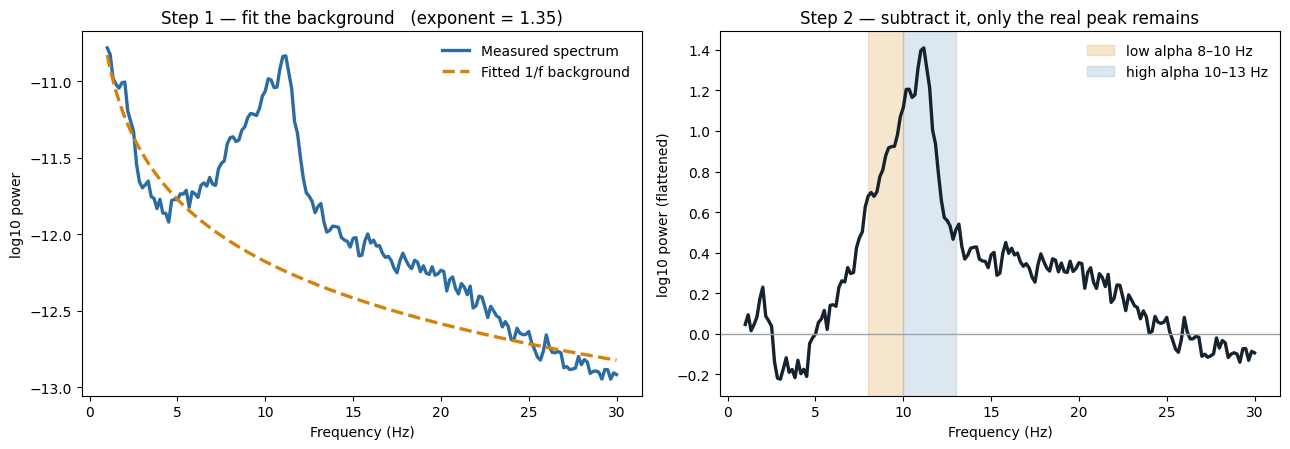

In [18]:
# ── รูปตัวอย่างการ fit: สเปกตรัมหนึ่งไฟล์ + เส้นพื้นหลัง 1/f + สเปกตรัมที่ลบพื้นหลังแล้ว ──
#    ใช้เป็นรูปอธิบายวิธีในสไลด์ · preprocessing เหมือน v4 ทุกบรรทัด
import mne, numpy as np, matplotlib.pyplot as plt, inspect
from mne.time_frequency import psd_array_welch
from specparam import SpectralModel

FILE      = 'Dataset/sub-608/ses-1/eeg/sub-608_ses-1_task-EyesClosed_acq-pre_eeg.edf'
OCC       = ['O1', 'Oz', 'O2', 'PO3', 'POz', 'PO4']
eog_proxy = ['Fp1', 'Fp2']
MUS_THR   = 0.9
mne.set_log_level('ERROR')

# ── preprocessing เหมือน v4 ทุกบรรทัด ───────────────────────────────────────
raw = mne.io.read_raw_edf(FILE, preload=True, verbose=False)
if raw.info['sfreq'] != 250:
    raw.resample(250, verbose=False)
raw.filter(0.5, 45., verbose=False)
raw.notch_filter(50., verbose=False)

n_comp = min(20, len(mne.pick_types(raw.info, eeg=True)) - 1)
ica = mne.preprocessing.ICA(n_components=n_comp, random_state=42,
                            max_iter='auto', verbose=False)
ica.fit(raw, decim=3, verbose=False)
bad = list(ica.find_bads_eog(raw, ch_name=[c for c in eog_proxy if c in raw.ch_names],
                             verbose=False)[0])
bad += [c for c in ica.find_bads_muscle(raw, threshold=MUS_THR, verbose=False)[0]
        if c not in bad]
ica.exclude = sorted(set(bad))
ica.apply(raw, verbose=False)
raw.set_eeg_reference('average', projection=False, verbose=False)

picks = [c for c in OCC if c in raw.ch_names]
sf    = raw.info['sfreq']
nfft, novl = int(sf * 6), int(sf * 3)
data  = raw.get_data(picks=picks)
gm    = np.all(np.abs(data) < 100e-6, axis=0)

_wk = {'window': 'hamming'} if 'window' in inspect.signature(psd_array_welch).parameters else {}
psds, freqs = psd_array_welch(data[:, gm], sfreq=sf, fmin=1, fmax=45,
                              n_fft=nfft, n_overlap=novl, verbose=False, **_wk)
power = psds.mean(axis=0)

fm = SpectralModel(peak_width_limits=[1, 8], max_n_peaks=6, peak_threshold=2.0,
                   min_peak_height=0.1, aperiodic_mode='fixed', verbose=False)
fm.fit(freqs, power, freq_range=[1, 30])
offset, exponent = fm.get_params('aperiodic')
print(f'offset = {offset:.3f}   exponent = {exponent:.3f}   '
      f'ICA removed {len(ica.exclude)} components')

# ── วาด ────────────────────────────────────────────────────────────────────
m    = (freqs >= 1) & (freqs <= 30)
f    = freqs[m]
orig = np.log10(power[m])
ap   = offset - exponent * np.log10(f)      # สูตรเดียวกับ corrected_band() ใน v4
flat = orig - ap

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))

ax[0].plot(f, orig, color='#2B6CA3', lw=2.4, label='Measured spectrum')
ax[0].plot(f, ap,   color='#D4820A', lw=2.4, ls='--', label='Fitted 1/f background')
ax[0].set_title(f'Step 1 — fit the background   (exponent = {exponent:.2f})')
ax[0].set_xlabel('Frequency (Hz)'); ax[0].set_ylabel('log10 power')
ax[0].legend(frameon=False)

ax[1].plot(f, flat, color='#16222E', lw=2.4)
ax[1].axhline(0, color='#9AA3AB', lw=1)
ax[1].axvspan(8, 10,  color='#D4820A', alpha=0.20, label='low alpha 8–10 Hz')
ax[1].axvspan(10, 13, color='#2B6CA3', alpha=0.16, label='high alpha 10–13 Hz')
ax[1].set_title('Step 2 — subtract it, only the real peak remains')
ax[1].set_xlabel('Frequency (Hz)'); ax[1].set_ylabel('log10 power (flattened)')
ax[1].legend(frameon=False)

plt.tight_layout()
plt.savefig('outputs/fooof_fit_example.png', dpi=150, bbox_inches='tight')
plt.show()

## ส่วนต่อยอด — คนวัยเดียวกัน เปลี่ยนเท่ากันไหม

คำถามนี้มาจากอาจารย์ ไม่อยู่ในแผนเดิม และไม่มีในเปเปอร์ต้นทาง

| ลำดับเซลล์ | ทำอะไร | ต้องรันก่อน |
|---|---|---|
| 1 | การกระจายของ Δ รายคน + ความสอดคล้องข้ามเงื่อนไข | `fooof_features_v4.csv` |
| 2 | Kruskal–Wallis เทียบกลุ่มอายุ + baseline/CI ที่ถูก | เซลล์ก่อนหน้า (ใช้ `d`, `p`) |
| 3 | split-half หลับตา — รันเต็ม ใช้เวลาราว 20 นาที | มี cache แล้วข้ามได้ |
| 4 | รูปฮิสโทแกรมแยกสีสามกลุ่ม — รูปที่ใช้ในสไลด์ | ต่อจากลำดับที่ 3 |
| 5 | split-half ลืมตา + แก้ attenuation ของ r(EO, EC) | `consistency_tested_*.csv` |

สรุปผลทั้งหมดอยู่ใน markdown เซลล์สุดท้ายของ notebook


อายุจาก: Dataset/participants.tsv
Δ รายคน: 3637 แถว · 608 คน · ตัววัด low_alpha_corr

=== ① ② ③ การกระจายของ Δ รายบุคคล ===
      task    region  group   n  median  iqr_lo  iqr_hi    iqr  pct_up  median_over_iqr  levene_p_across_groups
EyesClosed   frontal  Young 203  0.0906  0.0005  0.2045 0.2040 74.8768           0.4440                  0.7762
EyesClosed   frontal Middle 175  0.1098  0.0165  0.1894 0.1729 78.8571           0.6351                  0.7762
EyesClosed   frontal  Older 230  0.0725 -0.0219  0.1979 0.2197 67.8261           0.3299                  0.7762
EyesClosed   central  Young 203  0.0823  0.0156  0.2014 0.1858 76.3547           0.4428                  0.8280
EyesClosed   central Middle 174  0.0968  0.0159  0.1965 0.1806 78.7356           0.5362                  0.8280
EyesClosed   central  Older 230  0.0886 -0.0017  0.1940 0.1957 74.3478           0.4527                  0.8280
EyesClosed occipital  Young 203  0.0896 -0.0063  0.2283 0.2346 71.4286           0.3819     

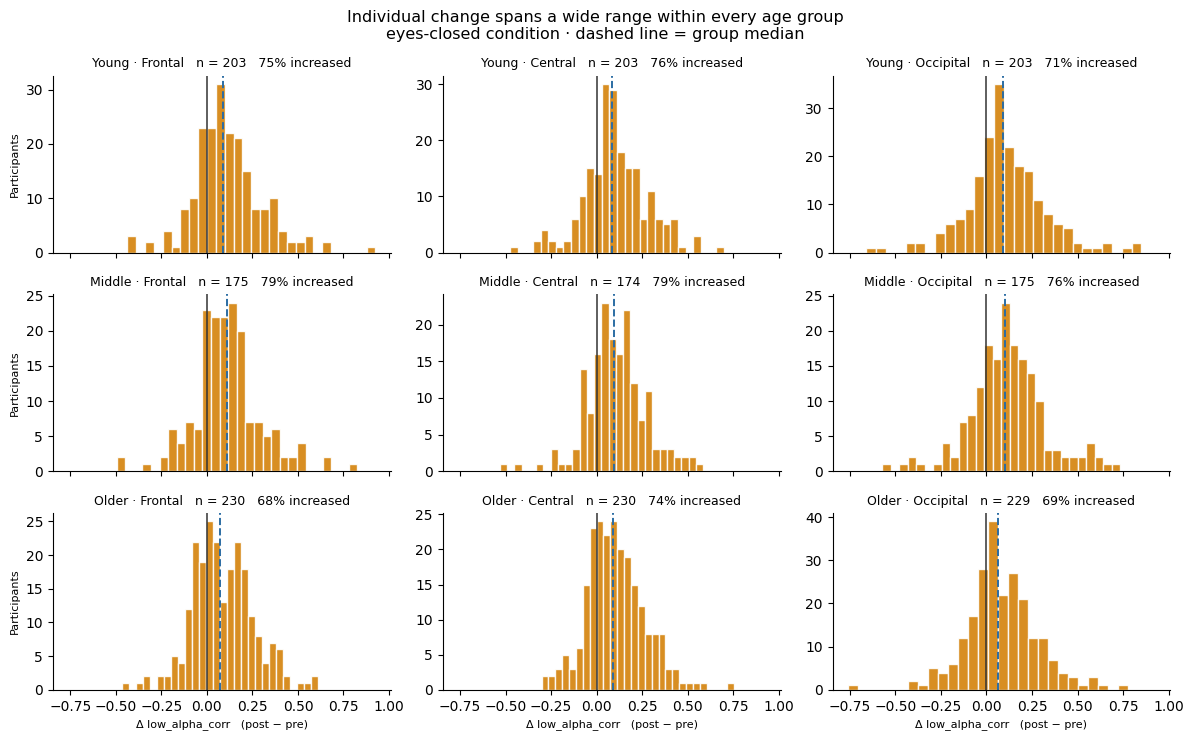

In [19]:
# ── Cell N — individual pre→post change: distribution, spread, reliability ──
import numpy as np, pandas as pd, matplotlib.pyplot as plt, glob
from scipy.stats import levene, spearmanr

MEAS = 'low_alpha_corr'     # เปลี่ยนเป็น 'ap_exponent' เพื่อดูอีกตัว
REG  = ['frontal', 'central', 'occipital']
GRP  = ['Young', 'Middle', 'Older']

df = pd.read_csv('outputs/fooof_features_v4.csv')
df = df[df['ap_exponent'] > 0].copy()

# แนบอายุ ถ้าไฟล์ยังไม่มี
if 'age' not in df.columns:
    cand = glob.glob('**/participants.tsv', recursive=True)
    assert cand, "ไม่เจอ participants.tsv — ใส่ path เอง"
    pt = pd.read_csv(cand[0], sep='\t')
    print(f"อายุจาก: {cand[0]}")
    df = df.merge(pt[['participant_id', 'age']],
                  left_on='subject', right_on='participant_id', how='left')

df['group'] = df['age'].apply(
    lambda a: 'Young' if a <= 34 else ('Older' if a >= 51 else 'Middle'))

# ── ① Δ รายคน ──
w = df.pivot_table(index=['subject','group','task','region'],
                   columns='condition', values=MEAS).dropna(subset=['pre','post'])
w['delta'] = w['post'] - w['pre']
d = w.reset_index()
print(f"Δ รายคน: {len(d)} แถว · {d.subject.nunique()} คน · ตัววัด {MEAS}\n")

# ── ② การกระจาย + ③ เทียบข้ามกลุ่มอายุ ──
rows = []
for tk in ['EyesClosed', 'EyesOpen']:
    for rg in REG:
        sub = d[(d.task == tk) & (d.region == rg)]
        samples = [sub[sub.group == g].delta.dropna().values for g in GRP]
        samples = [s for s in samples if len(s) > 2]
        # Brown-Forsythe: ทดสอบว่า "ความกว้าง" ของการกระจายต่างกันไหม ไม่ใช่ค่ากลาง
        lev_p = levene(*samples, center='median')[1] if len(samples) == 3 else np.nan
        for g in GRP:
            s = sub[sub.group == g].delta.dropna()
            if len(s) < 3: continue
            q1, q2, q3 = s.quantile([.25, .50, .75])
            rows.append({'task': tk, 'region': rg, 'group': g, 'n': len(s),
                         'median': q2, 'iqr_lo': q1, 'iqr_hi': q3, 'iqr': q3 - q1,
                         'pct_up': (s > 0).mean() * 100,
                         'median_over_iqr': q2 / (q3 - q1) if q3 > q1 else np.nan,
                         'levene_p_across_groups': lev_p})
dist = pd.DataFrame(rows)
print("=== ① ② ③ การกระจายของ Δ รายบุคคล ===")
print(dist.round(4).to_string(index=False))
dist.to_csv(f'outputs/individual_delta_{MEAS}.csv', index=False)

# ── ④ reliability: คนเดียวกันขยับทางเดียวกันทั้งสองเงื่อนไขไหม ──
p = d.pivot_table(index=['subject','group','region'],
                  columns='task', values='delta').dropna().reset_index()
p['same_dir'] = np.sign(p.EyesOpen) == np.sign(p.EyesClosed)

print("\n=== ④ ความสอดคล้องข้ามเงื่อนไข (cross-condition consistency) ===")
print("คนละตัวกับ split-half reliability ในเซลล์ถัด ๆ ไป — อันนั้นวัดความคงเส้นภายในเงื่อนไขเดียว")
rel = []
for rg in REG:
    g = p[p.region == rg]
    if len(g) < 10: continue
    r, pv = spearmanr(g.EyesOpen, g.EyesClosed)
    rel.append({'region': rg, 'n': len(g), 'same_dir_pct': g.same_dir.mean()*100,
                'spearman_r': r, 'p': pv})
rel = pd.DataFrame(rel)
print(rel.round(4).to_string(index=False))
# same_dir 50% ไม่ใช่ baseline — ถ้าส่วนใหญ่ขยับขึ้นทั้งสองเงื่อนไข ทิศก็ตรงกันได้เอง
# โดยไม่ต้องมีความสัมพันธ์ระหว่างคน · baseline ที่ถูกคิดจาก marginal อยู่ในเซลล์ถัดไป
print("→ อย่าอ่าน same_dir เทียบ 50% ให้ดู chance_baseline ในเซลล์ถัดไป")
rel.to_csv(f'outputs/individual_reliability_{MEAS}.csv', index=False)

# ── รูป: histogram ของ Δ แยกกลุ่มอายุ × บริเวณ (เฉพาะหลับตา) ──
# ── Figure: distribution of individual change, age group × region (eyes-closed) ──
ec = d[d.task == 'EyesClosed']
fig, axes = plt.subplots(len(GRP), len(REG), figsize=(12, 7.5), sharex=True)
for i, g in enumerate(GRP):
    for j, rg in enumerate(REG):
        ax, s = axes[i, j], ec[(ec.group == g) & (ec.region == rg)].delta.dropna()
        ax.hist(s, bins=28, color='#d4820a', edgecolor='white', alpha=.9)
        ax.axvline(0, color='#333', lw=1.1)
        ax.axvline(s.median(), color='#2b6ca3', ls='--', lw=1.4)
        ax.set_title(f"{g} · {rg.capitalize()}   n = {len(s)}   "
                     f"{(s > 0).mean()*100:.0f}% increased", fontsize=9)
        ax.spines[['top', 'right']].set_visible(False)
        if i == len(GRP) - 1:
            ax.set_xlabel(f'Δ {MEAS}   (post − pre)', fontsize=8)
        if j == 0:
            ax.set_ylabel('Participants', fontsize=8)
fig.suptitle('Individual change spans a wide range within every age group\n'
             'eyes-closed condition · dashed line = group median',
             fontsize=11.5)
plt.tight_layout()
plt.savefig(f'outputs/individual_delta_{MEAS}.png', dpi=150, bbox_inches='tight')
plt.show()

In [20]:
# ── Cell N+1 — age-group comparison + proper baseline/CI for consistency ──
import numpy as np, pandas as pd
from scipy.stats import kruskal, mannwhitneyu, spearmanr

RNG = np.random.default_rng(42)
# d และ p มาจากเซลล์ก่อนหน้า

# ══ ① Δ ต่างกันระหว่างกลุ่มอายุไหม (ค่ากลาง ไม่ใช่ความกว้าง) ══
rows = []
for tk in ['EyesClosed', 'EyesOpen']:
    for rg in REG:
        sub = d[(d.task == tk) & (d.region == rg)]
        s = {g: sub[sub.group == g].delta.dropna().values for g in GRP}
        H, pv = kruskal(*s.values())
        N = sum(len(v) for v in s.values())
        eps2 = (H - len(GRP) + 1) / (N - len(GRP))      # epsilon-squared
        row = {'task': tk, 'region': rg, 'H': H, 'p_raw': pv,
               'epsilon_sq': eps2, 'n': N}
        for a, b in [('Young','Middle'), ('Young','Older'), ('Middle','Older')]:
            row[f'{a[0]}v{b[0]}_p'] = mannwhitneyu(s[a], s[b])[1]
        rows.append(row)

kw = pd.DataFrame(rows)
# Holm ปรับ 6 การทดสอบหลัก
o = kw.p_raw.values.argsort()
holm = np.empty(len(kw)); run = 0.0
for i, idx in enumerate(o):
    run = max(run, kw.p_raw.values[idx] * (len(kw) - i))
    holm[idx] = min(run, 1.0)
kw['p_holm'] = holm

print("=== ① ขนาดการเปลี่ยนแปลงต่างกันระหว่างกลุ่มอายุไหม (Kruskal–Wallis) ===")
print(kw.round(4).to_string(index=False))
print("epsilon² : 0.01 เล็ก · 0.06 ปานกลาง · 0.14 ใหญ่")
kw.to_csv(f'outputs/age_group_delta_{MEAS}.csv', index=False)

# ══ ② baseline ที่ถูกต้องของ same_dir + CI ของ Spearman ══
print("\n=== ② ความสอดคล้องข้ามเงื่อนไข เทียบ baseline ที่ถูก ===")
out = []
for rg in REG:
    g = p[p.region == rg]
    a, b = (g.EyesClosed > 0).mean(), (g.EyesOpen > 0).mean()
    chance = a * b + (1 - a) * (1 - b)        # ถ้าทิศเป็นอิสระต่อกัน
    obs = g.same_dir.mean()
    r_obs = spearmanr(g.EyesOpen, g.EyesClosed)[0]

    # permutation: สลับคู่ EO ข้ามคน เก็บสัดส่วนขึ้น-ลงเดิมไว้
    perm_s, perm_r = [], []
    eo, ec = g.EyesOpen.values, g.EyesClosed.values
    for _ in range(2000):
        sh = RNG.permutation(eo)
        perm_s.append((np.sign(sh) == np.sign(ec)).mean())
        perm_r.append(spearmanr(sh, ec)[0])
    p_same = (np.sum(np.array(perm_s) >= obs) + 1) / 2001
    p_r    = (np.sum(np.array(perm_r) >= r_obs) + 1) / 2001

    # bootstrap CI ของ r (สุ่มคนใหม่)
    boot = [spearmanr(*g.iloc[RNG.integers(0, len(g), len(g))]
                      [['EyesOpen','EyesClosed']].values.T)[0] for _ in range(2000)]
    lo, hi = np.percentile(boot, [2.5, 97.5])

    out.append({'region': rg, 'n': len(g),
                'same_dir': obs * 100, 'chance_baseline': chance * 100,
                'excess_pts': (obs - chance) * 100, 'perm_p_same': p_same,
                'spearman_r': r_obs, 'ci_lo': lo, 'ci_hi': hi, 'perm_p_r': p_r})

rel2 = pd.DataFrame(out)
print(rel2.round(4).to_string(index=False))
rel2.to_csv(f'outputs/consistency_tested_{MEAS}.csv', index=False)

=== ① ขนาดการเปลี่ยนแปลงต่างกันระหว่างกลุ่มอายุไหม (Kruskal–Wallis) ===
      task    region      H  p_raw  epsilon_sq   n  YvM_p  YvO_p  MvO_p  p_holm
EyesClosed   frontal 2.8173 0.2445      0.0014 608 0.8792 0.1574 0.1506  0.7913
EyesClosed   central 0.3086 0.8570     -0.0028 607 0.7397 0.7921 0.5928  0.9196
EyesClosed occipital 3.2407 0.1978      0.0021 607 0.5240 0.2557 0.0782  0.7913
  EyesOpen   frontal 6.0449 0.0487      0.0068 602 0.0171 0.0884 0.4282  0.2921
  EyesOpen   central 1.5540 0.4598     -0.0007 607 0.2999 0.2659 0.9568  0.9196
  EyesOpen occipital 4.9934 0.0824      0.0050 606 0.0380 0.0860 0.5787  0.4118
epsilon² : 0.01 เล็ก · 0.06 ปานกลาง · 0.14 ใหญ่

=== ② ความสอดคล้องข้ามเงื่อนไข เทียบ baseline ที่ถูก ===
   region   n  same_dir  chance_baseline  excess_pts  perm_p_same  spearman_r  ci_lo  ci_hi  perm_p_r
  frontal 602   59.8007          54.7466      5.0540       0.0030      0.2867 0.2095 0.3640    0.0005
  central 606   65.8416          62.2864      3.5552      

In [21]:
# ══════════════════════════════════════════════════════════════════════════
#  split-half reliability ของ Δ รายบุคคล  (EyesClosed เท่านั้น)
#  รันเต็ม — ตั้งค่าตรงกับ NB5b cell 10 (v4) ทุกจุด · ตรวจแล้วได้ r = 1.0000
#  ตอบว่า: การกระจายของ Δ ที่เห็น เป็นความต่างระหว่างคนจริง หรือเป็น noise
# ══════════════════════════════════════════════════════════════════════════
import os, glob, inspect, warnings, numpy as np, pandas as pd, mne
from mne.time_frequency import psd_array_welch
from scipy.stats import spearmanr
from specparam import SpectralModel
warnings.filterwarnings('ignore')
mne.set_log_level('ERROR')
 
N_SUB = None            # ← รันเต็มทุกคน
STOP_ON_ERROR = False   # ← ข้ามไฟล์ที่พัง แล้วรันต่อ
SF    = 250             # เหมือน v4
EPOCH = 6.0             # วินาทีต่อท่อน
FIT   = [1, 30]         # FIT_MAIN ของ v4
BAND  = (8, 10)         # low alpha
MEAS  = 'low_alpha_corr'
CACHE = 'outputs/splithalf_features_v2.csv'      # ชื่อใหม่ ไม่ปนกับ cache เก่า
 
REGIONS = {'frontal':   ['F3','Fz','F4','F7','F8','AF3','AF4'],
           'central':   ['C3','Cz','C4','FC1','FC2','CP1','CP2'],
           'occipital': ['O1','Oz','O2','PO3','POz','PO4']}
EOG = ['Fp1','Fp2']
 
_wkw = {}
if 'window' in inspect.signature(psd_array_welch).parameters:
    _wkw['window'] = 'hamming'
 
 
def fit_ap(freqs, power):
    """คืน (offset, exponent) — ตั้งค่าเหมือน fit_fooof ของ v4 เป๊ะ"""
    fm = SpectralModel(peak_width_limits=[1, 8], max_n_peaks=6,
                       peak_threshold=2.0, min_peak_height=0.1,
                       aperiodic_mode='fixed', verbose=False)
    fm.fit(freqs, power, freq_range=FIT)
    off, exp = fm.get_params('aperiodic')
    return float(off), float(exp)
 
 
def corrected_band(freqs, power, offset, exponent, lo, hi):
    """เหมือน corrected_band ของ v4 เป๊ะ"""
    m  = (freqs >= lo) & (freqs < hi)
    ap = offset - exponent * np.log10(freqs[m])
    return (np.log10(power[m]) - ap).mean()
 
 
def measure(freqs, power):
    off, exp = fit_ap(freqs, power)
    return corrected_band(freqs, power, off, exp, *BAND), exp
 
 
# ── 1. สกัดฟีเจอร์ของแต่ละครึ่ง ───────────────────────────────────────────
files = sorted(glob.glob('Dataset/sub-*/ses-1/eeg/*task-EyesClosed*_eeg.edf'))
assert files, "ไม่เจอไฟล์ .edf — เช็ค path"
subs = sorted({os.path.basename(f).split('_')[0] for f in files})
if N_SUB:
    subs  = subs[:N_SUB]
    files = [f for f in files if os.path.basename(f).split('_')[0] in subs]
 
done = set(pd.read_csv(CACHE)['file']) if os.path.exists(CACHE) else set()
todo = [f for f in files if os.path.basename(f) not in done]
print(f"{len(files)} ไฟล์ · {len(subs)} คน · ทำแล้ว {len(done)} · เหลือ {len(todo)}")
 
import time
_t0 = time.time()
rows, n_skip = [], 0
for i, fpath in enumerate(todo, 1):
    fname = os.path.basename(fpath)
    parts = fname.replace('_eeg.edf', '').split('_')
    subj, acq = parts[0], parts[3].replace('acq-', '')
    try:
        raw = mne.io.read_raw_edf(fpath, preload=True, verbose=False)
        if raw.info['sfreq'] != SF:
            raw.resample(SF, verbose=False)
        raw.filter(0.5, 45., verbose=False)
        raw.notch_filter(50., verbose=False)
 
        n_exc = -1
        try:
            n_comp = min(20, len(mne.pick_types(raw.info, eeg=True)) - 1)
            ica = mne.preprocessing.ICA(n_components=n_comp, random_state=42,
                                        max_iter='auto', verbose=False)
            ica.fit(raw, decim=3, verbose=False)
            bad = []
            eog_ch = [c for c in EOG if c in raw.ch_names]
            if eog_ch:
                bad += list(ica.find_bads_eog(raw, ch_name=eog_ch, verbose=False)[0])
            try:
                bad += [c for c in ica.find_bads_muscle(raw, threshold=0.9,
                                                        verbose=False)[0] if c not in bad]
            except Exception:
                pass
            ica.exclude = sorted(set(bad))
            ica.apply(raw, verbose=False)
            n_exc = len(ica.exclude)
        except Exception:
            pass
 
        raw.set_eeg_reference('average', projection=False, verbose=False)
        sf    = raw.info['sfreq']
        n_fft = int(sf * 6)
        n_ovl = int(sf * 3)
        L     = int(EPOCH * sf)
 
        for rg, chs in REGIONS.items():
            picks = [c for c in chs if c in raw.ch_names]
            if not picks:
                continue
            data = raw.get_data(picks=picks)
            good = np.all(np.abs(data) < 100e-6, axis=0)      # ±100 µV เหมือน v4
            if good.sum() < n_fft * 2:
                continue
            clean = data[:, good]
 
            # ── full : ทำเหมือน v4 เป๊ะ (Welch ซ้อน 50% ทั้งเส้น) ──
            psds, freqs = psd_array_welch(clean, sfreq=sf, fmin=1, fmax=45,
                                          n_fft=n_fft, n_overlap=n_ovl,
                                          verbose=False, **_wkw)
            a_full, e_full = measure(freqs, psds.mean(axis=0))
 
            # ── ครึ่ง A / B : ท่อนคี่ กับ ท่อนคู่ ──
            blocks = np.stack([clean[:, s:s+L]
                               for s in range(0, clean.shape[1] - L + 1, L)])
            if len(blocks) < 6:
                continue
            halves = {'A': blocks[0::2], 'B': blocks[1::2], 'full': None}
            res = {'full': (a_full, e_full)}
            for h in ('A', 'B'):
                ps, fr = psd_array_welch(halves[h], sfreq=sf, fmin=1, fmax=45,
                                         n_fft=L, n_overlap=0,
                                         verbose=False, **_wkw)
                res[h] = measure(fr, ps.mean(axis=(0, 1)))
 
            for h, (a, e) in res.items():
                rows.append({'file': fname, 'subject': subj, 'condition': acq,
                             'region': rg, 'half': h,
                             'low_alpha_corr': a, 'ap_exponent': e,
                             'n_block': len(blocks), 'n_ica_excluded': n_exc})
    except Exception as ex:
        print(f"  ข้าม {fname}: {type(ex).__name__}: {ex}")
        n_skip += 1
        if STOP_ON_ERROR:
            raise
 
    if i % 25 == 0:
        if rows:
            pd.DataFrame(rows).to_csv(CACHE, mode='a', index=False,
                                      header=not os.path.exists(CACHE))
            rows = []
        el = time.time() - _t0
        print(f"  {i}/{len(todo)} · ข้าม {n_skip} · ผ่านไป {el/60:.1f} นาที · เหลืออีกราว {(len(todo)-i)*el/i/60:.0f} นาที")
 
if rows:
    pd.DataFrame(rows).to_csv(CACHE, mode='a', index=False,
                              header=not os.path.exists(CACHE))
 
assert os.path.exists(CACHE), "ไม่มีไฟล์ไหนผ่านเลย — ดู error ด้านบน"
sh = pd.read_csv(CACHE).drop_duplicates(['file', 'region', 'half'])
print(f"\nได้ {len(sh)} แถว · {sh.subject.nunique()} คน")
 
 
# ── 2. ตรวจว่าตรงกับ v4 ไหม — ตอนนี้ควรใกล้ 1.00 ไม่ใช่ 0.955 ───────────
v4  = pd.read_csv('outputs/fooof_features_v4.csv')
chk = (sh[sh.half == 'full']
       .merge(v4[v4.task == 'EyesClosed'][['subject', 'condition', 'region', MEAS]],
              on=['subject', 'condition', 'region'], suffixes=('_new', '_v4'))
       .dropna())
r_chk = chk[f'{MEAS}_new'].corr(chk[f'{MEAS}_v4'])
print(f"เทียบกับ v4 : n={len(chk)}  r={r_chk:.4f}   (ควร > 0.99)")
if r_chk < 0.99:
    print("⚠️  ยังไม่ตรงกับ v4 สนิท — ตรวจการตั้งค่าอีกรอบก่อนเชื่อผล")
 
 
# ── 3. split-half reliability ────────────────────────────────────────────
w = sh.pivot_table(index=['subject', 'region', 'half'],
                   columns='condition', values=MEAS).dropna(subset=['pre', 'post'])
w['delta'] = w['post'] - w['pre']
dd = (w.reset_index()
        .pivot_table(index=['subject', 'region'], columns='half', values='delta')
        .dropna().reset_index())
 
out = []
for rg, g in dd.groupby('region'):
    r_half = spearmanr(g.A, g.B)[0]
    out.append({'region': rg, 'n': len(g),
                'r_half': r_half,
                'reliability_SB': 2 * r_half / (1 + r_half),     # Spearman–Brown
                'sd_observed': g['full'].std(),
                'sd_true_est': g['full'].std() * np.sqrt(max(2*r_half/(1+r_half), 0)),
                'pct_down_observed': (g['full'] < 0).mean() * 100,
                'down_both_halves':  ((g.A < 0) & (g.B < 0)).mean() * 100,
                'up_both_halves':    ((g.A > 0) & (g.B > 0)).mean() * 100,
                'halves_disagree':   (np.sign(g.A) != np.sign(g.B)).mean() * 100})
 
res = pd.DataFrame(out)
print(f"\n=== split-half reliability ของ Δ {MEAS} ===")
print(res.round(3).to_string(index=False))
res.to_csv(f'outputs/splithalf_reliability_v2_{MEAS}.csv', index=False)
print("""
reliability_SB     สัดส่วนความแปรปรวนของ Δ ที่เป็นความต่างระหว่างคนจริง (ขอบบน)
down_both_halves   ลดลงสอดคล้องกันทั้งสองครึ่ง — ไม่ใช่ขอบล่างของคนที่ลดลงจริง
                   เพราะคนที่ไม่เปลี่ยนเลยก็ติดลบพร้อมกันได้ราว 25% จากความบังเอิญ
halves_disagree    คนที่ Δ เชื่อไม่ได้ สองครึ่งให้คำตอบคนละทิศ
หมายเหตุ  split-half เห็นเฉพาะ noise ภายในไฟล์เดียว ไม่เห็นหมวกขยับหรือเจลแห้งระหว่างเซสชัน""")

1216 ไฟล์ · 608 คน · ทำแล้ว 1216 · เหลือ 0

ได้ 10944 แถว · 608 คน
เทียบกับ v4 : n=3648  r=1.0000   (ควร > 0.99)

=== split-half reliability ของ Δ low_alpha_corr ===
   region   n  r_half  reliability_SB  sd_observed  sd_true_est  pct_down_observed  down_both_halves  up_both_halves  halves_disagree
  central 608   0.769           0.869        0.167        0.156             23.684            15.954          66.118           17.928
  frontal 608   0.723           0.839        0.181        0.166             26.645            17.434          63.816           18.750
occipital 608   0.778           0.875        0.207        0.194             28.125            19.901          63.158           16.941

reliability_SB     สัดส่วนความแปรปรวนของ Δ ที่เป็นความต่างระหว่างคนจริง (ขอบบน)
down_both_halves   ลดลงสอดคล้องกันทั้งสองครึ่ง — ไม่ใช่ขอบล่างของคนที่ลดลงจริง
                   เพราะคนที่ไม่เปลี่ยนเลยก็ติดลบพร้อมกันได้ราว 25% จากความบังเอิญ
halves_disagree    คนที่ Δ เชื่อไม่ได้ สองครึ่งให้คำตอบ

In [22]:
# รันใหม่เฉพาะส่วนวิเคราะห์ของ EC — ไม่แตะไฟล์ .edf
# เซลล์นี้แทนตารางของเซลล์ก่อน โดยเพิ่ม quality filter ap_exponent > 0 ให้ตรงกับ v4
# ค่าเท่าเดิมทุกตัวเมื่อปัดเหลือสามตำแหน่ง · เขียนทับ splithalf_reliability_v2_*.csv เดิม
# ตัวเลขที่รายงานในสไลด์กับ markdown ท้ายไฟล์ มาจากเซลล์นี้
MEAS = 'low_alpha_corr'
sh = pd.read_csv('outputs/splithalf_features_v2.csv').drop_duplicates(
        ['file','region','half'])
sh = sh[sh.ap_exponent > 0]                    # ← บรรทัดที่เพิ่ม

w = sh.pivot_table(index=['subject','region','half'],
                   columns='condition', values=MEAS).dropna(subset=['pre','post'])
w['delta'] = w['post'] - w['pre']
dd = (w.reset_index()
        .pivot_table(index=['subject','region'], columns='half', values='delta')
        .dropna().reset_index())

out = []
for rg, g in dd.groupby('region'):
    r_half = spearmanr(g.A, g.B)[0]
    rel    = 2 * r_half / (1 + r_half)
    out.append({'region': rg, 'n': len(g), 'r_half': r_half, 'reliability_SB': rel,
                'sd_observed': g['full'].std(),
                'sd_true_est': g['full'].std() * np.sqrt(max(rel, 0)),
                'pct_down_observed': (g['full'] < 0).mean() * 100,
                'down_both_halves': ((g.A < 0) & (g.B < 0)).mean() * 100,
                'up_both_halves':   ((g.A > 0) & (g.B > 0)).mean() * 100,
                'halves_disagree':  (np.sign(g.A) != np.sign(g.B)).mean() * 100})
res = pd.DataFrame(out)
print(res.round(3).to_string(index=False))
res.to_csv(f'outputs/splithalf_reliability_v2_{MEAS}.csv', index=False)

   region   n  r_half  reliability_SB  sd_observed  sd_true_est  pct_down_observed  down_both_halves  up_both_halves  halves_disagree
  central 607   0.769           0.869        0.167        0.156             23.723            15.980          66.063           17.957
  frontal 608   0.723           0.839        0.181        0.166             26.645            17.434          63.816           18.750
occipital 607   0.778           0.875        0.207        0.194             28.007            19.769          63.262           16.969


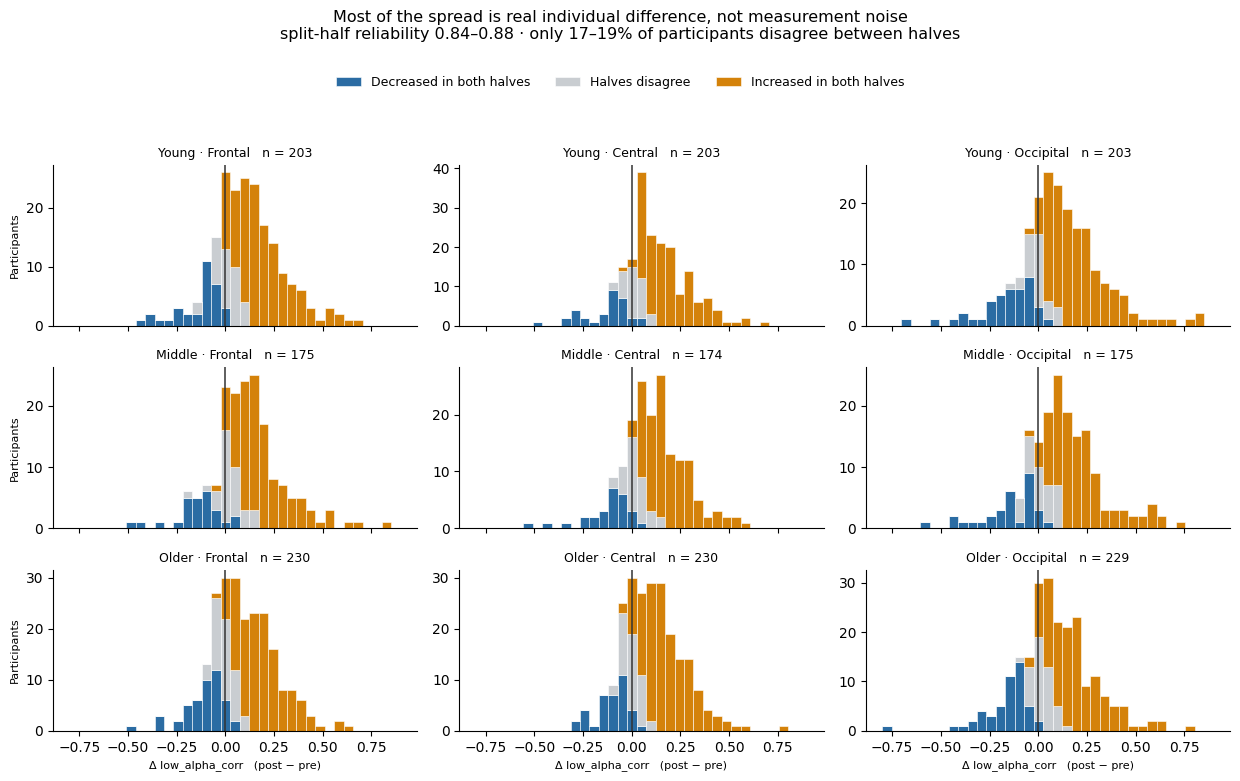

ขนาด |Δ| มัธยฐาน แยกตามกลุ่ม:
cat
down    0.108
mix     0.035
up      0.164


In [23]:
# ── รูป: ฮิสโทแกรม Δ แยกสีตามว่าสองครึ่งตรงกันไหม (อายุ × บริเวณ) — รูปที่ใช้ในสไลด์ ──
#    ต้องรันเซลล์ split-half หลับตาก่อน เพราะใช้ dd จากเซลล์นั้น
import matplotlib.pyplot as plt, glob

pt = pd.read_csv(glob.glob('**/participants.tsv', recursive=True)[0], sep='\t')
g3 = dd.merge(pt[['participant_id','age']], left_on='subject',
              right_on='participant_id', how='left')
g3['group'] = g3['age'].apply(
    lambda a: 'Young' if a <= 34 else ('Older' if a >= 51 else 'Middle'))

def cat(r):
    if r.A < 0 and r.B < 0: return 'down'
    if r.A > 0 and r.B > 0: return 'up'
    return 'mix'
g3['cat'] = g3.apply(cat, axis=1)

GRP = ['Young','Middle','Older']; REG = ['frontal','central','occipital']
COL = {'up':'#d4820a', 'down':'#2b6ca3', 'mix':'#c9cdd1'}
LAB = {'up':   'Increased in both halves',
       'down': 'Decreased in both halves',
       'mix':  'Halves disagree'}
bins = np.linspace(-0.8, 0.9, 36)

fig, axes = plt.subplots(len(GRP), len(REG), figsize=(12.5, 7.8), sharex=True)
for i, gr in enumerate(GRP):
    for j, rg in enumerate(REG):
        ax = axes[i, j]
        sub = g3[(g3.group == gr) & (g3.region == rg)]
        ax.hist([sub[sub.cat == c]['full'] for c in ('down','mix','up')],
                bins=bins, stacked=True,
                color=[COL['down'], COL['mix'], COL['up']],
                label=[LAB['down'], LAB['mix'], LAB['up']], edgecolor='white',
                linewidth=.4)
        ax.axvline(0, color='#333', lw=1.1)
        ax.set_title(f"{gr} · {rg.capitalize()}   n = {len(sub)}", fontsize=9)
        ax.spines[['top','right']].set_visible(False)
        if j == 0: ax.set_ylabel('Participants', fontsize=8)
        if i == len(GRP)-1: ax.set_xlabel('Δ low_alpha_corr   (post − pre)', fontsize=8)

h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc='upper center', bbox_to_anchor=(0.5, 0.925),
           ncol=3, fontsize=9, frameon=False)
fig.suptitle('Most of the spread is real individual difference, not measurement noise\n'
             'split-half reliability 0.84–0.88 · only 17–19% of participants '
             'disagree between halves', fontsize=11.5, y=0.995)
plt.tight_layout(rect=[0, 0, 1, 0.90])
plt.savefig('outputs/individual_delta_bycat.png', dpi=150, bbox_inches='tight')
plt.show()
# ── ขนาดของ Δ ในแต่ละกลุ่ม — ที่มาของตัวเลข 0.035 / 0.108 / 0.163 ใน markdown ──
#    คนที่สองครึ่งไม่ตรงกัน (mix) คือคนที่ Δ เล็กอยู่แล้ว ไม่ใช่คนที่เปลี่ยนเยอะ
print("ขนาด |Δ| มัธยฐาน แยกตามกลุ่ม:")
print(g3.groupby('cat')['full'].apply(lambda s: s.abs().median()).round(3).to_string())

In [24]:
# ══════════════════════════════════════════════════════════════════════════
#  split-half reliability ของ Δ รายบุคคล  (EyesOpen)
#  EyesOpen — เพื่อแก้ attenuation ของ r(EO, EC)
#  ตอบว่า: การกระจายของ Δ ที่เห็น เป็นความต่างระหว่างคนจริง หรือเป็น noise
# ══════════════════════════════════════════════════════════════════════════
import os, glob, inspect, warnings, numpy as np, pandas as pd, mne
from mne.time_frequency import psd_array_welch
from scipy.stats import spearmanr
from specparam import SpectralModel
warnings.filterwarnings('ignore')
mne.set_log_level('ERROR')
 
N_SUB = None            # ← รันเต็มทุกคน
STOP_ON_ERROR = False   # ← ข้ามไฟล์ที่พัง แล้วรันต่อ
SF    = 250             # เหมือน v4
EPOCH = 6.0             # วินาทีต่อท่อน
FIT   = [1, 30]         # FIT_MAIN ของ v4
BAND  = (8, 10)         # low alpha
MEAS  = 'low_alpha_corr'
CACHE = 'outputs/splithalf_features_EO.csv'      # แยกจากของ EyesClosed
 
REGIONS = {'frontal':   ['F3','Fz','F4','F7','F8','AF3','AF4'],
           'central':   ['C3','Cz','C4','FC1','FC2','CP1','CP2'],
           'occipital': ['O1','Oz','O2','PO3','POz','PO4']}
EOG = ['Fp1','Fp2']
 
_wkw = {}
if 'window' in inspect.signature(psd_array_welch).parameters:
    _wkw['window'] = 'hamming'
 
 
def fit_ap(freqs, power):
    """คืน (offset, exponent) — ตั้งค่าเหมือน fit_fooof ของ v4 เป๊ะ"""
    fm = SpectralModel(peak_width_limits=[1, 8], max_n_peaks=6,
                       peak_threshold=2.0, min_peak_height=0.1,
                       aperiodic_mode='fixed', verbose=False)
    fm.fit(freqs, power, freq_range=FIT)
    off, exp = fm.get_params('aperiodic')
    return float(off), float(exp)
 
 
def corrected_band(freqs, power, offset, exponent, lo, hi):
    """เหมือน corrected_band ของ v4 เป๊ะ"""
    m  = (freqs >= lo) & (freqs < hi)
    ap = offset - exponent * np.log10(freqs[m])
    return (np.log10(power[m]) - ap).mean()
 
 
def measure(freqs, power):
    off, exp = fit_ap(freqs, power)
    return corrected_band(freqs, power, off, exp, *BAND), exp
 
 
# ── 1. สกัดฟีเจอร์ของแต่ละครึ่ง ───────────────────────────────────────────
files = sorted(glob.glob('Dataset/sub-*/ses-1/eeg/*task-EyesOpen*_eeg.edf'))
assert files, "ไม่เจอไฟล์ .edf — เช็ค path"
subs = sorted({os.path.basename(f).split('_')[0] for f in files})
if N_SUB:
    subs  = subs[:N_SUB]
    files = [f for f in files if os.path.basename(f).split('_')[0] in subs]
 
done = set(pd.read_csv(CACHE)['file']) if os.path.exists(CACHE) else set()
todo = [f for f in files if os.path.basename(f) not in done]
print(f"{len(files)} ไฟล์ · {len(subs)} คน · ทำแล้ว {len(done)} · เหลือ {len(todo)}")
 
import time
_t0 = time.time()
rows, n_skip = [], 0
for i, fpath in enumerate(todo, 1):
    fname = os.path.basename(fpath)
    parts = fname.replace('_eeg.edf', '').split('_')
    subj, acq = parts[0], parts[3].replace('acq-', '')
    try:
        raw = mne.io.read_raw_edf(fpath, preload=True, verbose=False)
        if raw.info['sfreq'] != SF:
            raw.resample(SF, verbose=False)
        raw.filter(0.5, 45., verbose=False)
        raw.notch_filter(50., verbose=False)
 
        n_exc = -1
        try:
            n_comp = min(20, len(mne.pick_types(raw.info, eeg=True)) - 1)
            ica = mne.preprocessing.ICA(n_components=n_comp, random_state=42,
                                        max_iter='auto', verbose=False)
            ica.fit(raw, decim=3, verbose=False)
            bad = []
            eog_ch = [c for c in EOG if c in raw.ch_names]
            if eog_ch:
                bad += list(ica.find_bads_eog(raw, ch_name=eog_ch, verbose=False)[0])
            try:
                bad += [c for c in ica.find_bads_muscle(raw, threshold=0.9,
                                                        verbose=False)[0] if c not in bad]
            except Exception:
                pass
            ica.exclude = sorted(set(bad))
            ica.apply(raw, verbose=False)
            n_exc = len(ica.exclude)
        except Exception:
            pass
 
        raw.set_eeg_reference('average', projection=False, verbose=False)
        sf    = raw.info['sfreq']
        n_fft = int(sf * 6)
        n_ovl = int(sf * 3)
        L     = int(EPOCH * sf)
 
        for rg, chs in REGIONS.items():
            picks = [c for c in chs if c in raw.ch_names]
            if not picks:
                continue
            data = raw.get_data(picks=picks)
            good = np.all(np.abs(data) < 100e-6, axis=0)      # ±100 µV เหมือน v4
            if good.sum() < n_fft * 2:
                continue
            clean = data[:, good]
 
            # ── full : ทำเหมือน v4 เป๊ะ (Welch ซ้อน 50% ทั้งเส้น) ──
            psds, freqs = psd_array_welch(clean, sfreq=sf, fmin=1, fmax=45,
                                          n_fft=n_fft, n_overlap=n_ovl,
                                          verbose=False, **_wkw)
            a_full, e_full = measure(freqs, psds.mean(axis=0))
 
            # ── ครึ่ง A / B : ท่อนคี่ กับ ท่อนคู่ ──
            blocks = np.stack([clean[:, s:s+L]
                               for s in range(0, clean.shape[1] - L + 1, L)])
            if len(blocks) < 6:
                continue
            halves = {'A': blocks[0::2], 'B': blocks[1::2], 'full': None}
            res = {'full': (a_full, e_full)}
            for h in ('A', 'B'):
                ps, fr = psd_array_welch(halves[h], sfreq=sf, fmin=1, fmax=45,
                                         n_fft=L, n_overlap=0,
                                         verbose=False, **_wkw)
                res[h] = measure(fr, ps.mean(axis=(0, 1)))
 
            for h, (a, e) in res.items():
                rows.append({'file': fname, 'subject': subj, 'condition': acq,
                             'region': rg, 'half': h,
                             'low_alpha_corr': a, 'ap_exponent': e,
                             'n_block': len(blocks), 'n_ica_excluded': n_exc})
    except Exception as ex:
        print(f"  ข้าม {fname}: {type(ex).__name__}: {ex}")
        n_skip += 1
        if STOP_ON_ERROR:
            raise
 
    if i % 25 == 0:
        if rows:
            pd.DataFrame(rows).to_csv(CACHE, mode='a', index=False,
                                      header=not os.path.exists(CACHE))
            rows = []
        el = time.time() - _t0
        print(f"  {i}/{len(todo)} · ข้าม {n_skip} · ผ่านไป {el/60:.1f} นาที · เหลืออีกราว {(len(todo)-i)*el/i/60:.0f} นาที")
 
if rows:
    pd.DataFrame(rows).to_csv(CACHE, mode='a', index=False,
                              header=not os.path.exists(CACHE))
 
assert os.path.exists(CACHE), "ไม่มีไฟล์ไหนผ่านเลย — ดู error ด้านบน"
sh = pd.read_csv(CACHE).drop_duplicates(['file', 'region', 'half'])
sh = sh[sh.ap_exponent > 0]          # ตัด fit ที่ล้มเหลว เหมือน v4
print(f"\nได้ {len(sh)} แถว · {sh.subject.nunique()} คน")
 
 
# ── 2. ตรวจว่าตรงกับ v4 ไหม — ตอนนี้ควรใกล้ 1.00 ไม่ใช่ 0.955 ───────────
v4  = pd.read_csv('outputs/fooof_features_v4.csv')
chk = (sh[sh.half == 'full']
       .merge(v4[v4.task == 'EyesOpen'][['subject', 'condition', 'region', MEAS]],
              on=['subject', 'condition', 'region'], suffixes=('_new', '_v4'))
       .dropna())
r_chk = chk[f'{MEAS}_new'].corr(chk[f'{MEAS}_v4'])
print(f"เทียบกับ v4 : n={len(chk)}  r={r_chk:.4f}   (ควร > 0.99)")
if r_chk < 0.99:
    print("⚠️  ยังไม่ตรงกับ v4 สนิท — ตรวจการตั้งค่าอีกรอบก่อนเชื่อผล")
 
 
# ── 3. split-half reliability ────────────────────────────────────────────
w = sh.pivot_table(index=['subject', 'region', 'half'],
                   columns='condition', values=MEAS).dropna(subset=['pre', 'post'])
w['delta'] = w['post'] - w['pre']
dd = (w.reset_index()
        .pivot_table(index=['subject', 'region'], columns='half', values='delta')
        .dropna().reset_index())
 
out = []
for rg, g in dd.groupby('region'):
    r_half = spearmanr(g.A, g.B)[0]
    out.append({'region': rg, 'n': len(g),
                'r_half': r_half,
                'reliability_SB': 2 * r_half / (1 + r_half),     # Spearman–Brown
                'sd_observed': g['full'].std(),
                'sd_true_est': g['full'].std() * np.sqrt(max(2*r_half/(1+r_half), 0)),
                'pct_down_observed': (g['full'] < 0).mean() * 100,
                'down_both_halves':  ((g.A < 0) & (g.B < 0)).mean() * 100,
                'up_both_halves':    ((g.A > 0) & (g.B > 0)).mean() * 100,
                'halves_disagree':   (np.sign(g.A) != np.sign(g.B)).mean() * 100})
 
res = pd.DataFrame(out)
print(f"\n=== split-half reliability ของ Δ {MEAS} ===")
print(res.round(3).to_string(index=False))
res.to_csv(f'outputs/splithalf_reliability_EO_{MEAS}.csv', index=False)
print("""
reliability_SB     สัดส่วนความแปรปรวนของ Δ ที่เป็นความต่างระหว่างคนจริง (ขอบบน)
down_both_halves   ลดลงสอดคล้องกันทั้งสองครึ่ง — ไม่ใช่ขอบล่างของคนที่ลดลงจริง
                   เพราะคนที่ไม่เปลี่ยนเลยก็ติดลบพร้อมกันได้ราว 25% จากความบังเอิญ
halves_disagree    คนที่ Δ เชื่อไม่ได้ สองครึ่งให้คำตอบคนละทิศ
หมายเหตุ  split-half เห็นเฉพาะ noise ภายในไฟล์เดียว ไม่เห็นหมวกขยับหรือเจลแห้งระหว่างเซสชัน""")
 
 
# ══════════════════════════════════════════════════════════════════════════
#  แก้ attenuation :  r_true = r_observed / sqrt(rel_EC x rel_EO)
# ══════════════════════════════════════════════════════════════════════════
con = pd.read_csv(f'outputs/consistency_tested_{MEAS}.csv')          # จากเซลล์ EO/EC
rEC = pd.read_csv(f'outputs/splithalf_reliability_v2_{MEAS}.csv')
rEO = pd.read_csv(f'outputs/splithalf_reliability_EO_{MEAS}.csv')
 
c = (con[['region', 'spearman_r', 'ci_lo', 'ci_hi']]
     .merge(rEC[['region', 'reliability_SB']], on='region')
     .merge(rEO[['region', 'reliability_SB']], on='region', suffixes=('_EC', '_EO')))
k = np.sqrt(c.reliability_SB_EC * c.reliability_SB_EO)
c['r_corrected'] = (c.spearman_r / k).clip(upper=1.0)
c['ci_lo_corr']  = (c.ci_lo / k).clip(upper=1.0)
c['ci_hi_corr']  = (c.ci_hi / k).clip(upper=1.0)
 
print("\n=== r(EO, EC) หลังแก้ attenuation ===")
print(c.round(3).to_string(index=False))
c.to_csv(f'outputs/attenuation_corrected_{MEAS}.csv', index=False)
print("""
วิธีอ่าน
  r_corrected ยังต่ำกว่าราว 0.5   -> การตอบสนองขึ้นกับเงื่อนไขจริง
  r_corrected ขึ้นไปราว 0.7 ขึ้นไป -> เป็นลักษณะประจำตัวพอสมควร แต่ตอนลืมตาวัดได้ไม่แม่น
  ระหว่างนั้น                      -> รายงานเป็นช่วง อย่าฟันธงข้างใดข้างหนึ่ง""")

1216 ไฟล์ · 608 คน · ทำแล้ว 1216 · เหลือ 0

ได้ 10923 แถว · 608 คน
เทียบกับ v4 : n=3639  r=1.0000   (ควร > 0.99)

=== split-half reliability ของ Δ low_alpha_corr ===
   region   n  r_half  reliability_SB  sd_observed  sd_true_est  pct_down_observed  down_both_halves  up_both_halves  halves_disagree
  central 605   0.657           0.793        0.156        0.138             26.612            17.851          59.174           22.975
  frontal 601   0.681           0.810        0.163        0.147             39.933            24.126          50.083           25.790
occipital 606   0.714           0.833        0.201        0.183             32.508            21.122          52.145           26.733

reliability_SB     สัดส่วนความแปรปรวนของ Δ ที่เป็นความต่างระหว่างคนจริง (ขอบบน)
down_both_halves   ลดลงสอดคล้องกันทั้งสองครึ่ง — ไม่ใช่ขอบล่างของคนที่ลดลงจริง
                   เพราะคนที่ไม่เปลี่ยนเลยก็ติดลบพร้อมกันได้ราว 25% จากความบังเอิญ
halves_disagree    คนที่ Δ เชื่อไม่ได้ สองครึ่งให้คำตอบ

In [25]:
# ══════════════════════════════════════════════════════════════════════════
#  ผลของความล้าขึ้นกับอายุไหม — เทียบ Δ (post − pre) ระหว่าง Young กับ Older
#  สร้าง outputs/age_fatigue_interaction.csv ซึ่ง NB6 อ่านต่อ
#
#  ต่างจากเซลล์สถิติหลัก (ที่ถามว่าแต่ละกลุ่มเปลี่ยนไหม) และต่างจากการเทียบ
#  ระดับ EEG ที่ baseline (ที่ถามว่าสองกลุ่มต่างกันไหมตั้งแต่ก่อนเริ่ม)
#  เซลล์นี้ถามว่า "สองกลุ่มเปลี่ยนไปในขนาดที่ต่างกันไหม"
# ══════════════════════════════════════════════════════════════════════════
import numpy as np, pandas as pd, glob
from scipy.stats import mannwhitneyu

ALPHA = 0.05
REG   = ['frontal', 'central', 'occipital']

# 6 ตัววัด × 3 บริเวณ = 18 ช่อง
#   low alpha ใส่ครบทั้งสามนิยาม เพราะข้ออ้างเรื่องอายุของเปเปอร์อยู่ที่ตัวนี้
#   จึงต้องแสดงว่าข้อสรุปไม่ขึ้นกับนิยามที่เลือก
MEAS = ['low_alpha_corr', 'low_alpha_rel', 'low_alpha_corr_rel',
        'high_alpha_corr', 'ap_exponent', 'ap_offset']

df = pd.read_csv('outputs/fooof_features_v4.csv')
missing = [m for m in MEAS if m not in df.columns]
assert not missing, f"ไม่มีคอลัมน์: {missing}"

df = df[df['ap_exponent'] > 0].copy()          # quality filter เดียวกับทุกเซลล์

cand = glob.glob('**/participants.tsv', recursive=True)
assert cand, "ไม่เจอ participants.tsv"
ages = pd.read_csv(cand[0], sep='\t').set_index('participant_id')['age']
df['group'] = df['subject'].map(ages).apply(
    lambda a: 'Young' if a <= 34 else ('Older' if a >= 51 else 'Middle'))

# ── จับคู่ก่อน–หลังของคนเดียวกัน เฉพาะหลับตา และเฉพาะสองกลุ่มตามเปเปอร์ ──
k = ['subject', 'group', 'task', 'region']
P = df[df.condition == 'pre' ].set_index(k)
Q = df[df.condition == 'post'].set_index(k)
M = P.join(Q, lsuffix='_pre', rsuffix='_post', how='inner').reset_index()
E = M[(M.task == 'EyesClosed') & (M.group != 'Middle')].copy()

print(f"ตัววัด {len(MEAS)} ตัว × บริเวณ {len(REG)} = {len(MEAS)*len(REG)} ช่อง")
print(E.groupby('group')['subject'].nunique().to_string(), "\n")

rows = []
for m in MEAS:
    for rg in REG:
        d = E[E.region == rg]
        y = (d[d.group == 'Young'][f'{m}_post'] - d[d.group == 'Young'][f'{m}_pre']).dropna()
        o = (d[d.group == 'Older'][f'{m}_post'] - d[d.group == 'Older'][f'{m}_pre']).dropna()
        if len(y) < 10 or len(o) < 10:
            continue
        U, p = mannwhitneyu(y, o, alternative='two-sided')
        rows.append({
            'measure': m, 'region': rg,
            'n_young': len(y), 'n_older': len(o),
            'median_change_young': np.median(y),
            'median_change_older': np.median(o),
            'diff_young_minus_older': np.median(y) - np.median(o),
            'rank_biserial': 2 * U / (len(y) * len(o)) - 1,   # ขนาดผล
            'U': U, 'p_raw': p,
        })

inter = pd.DataFrame(rows)
inter['p_bonf'] = (inter['p_raw'] * len(inter)).clip(upper=1.0)   # Bonferroni ทั้ง 18
inter['sig']    = inter['p_bonf'] < ALPHA
inter['region'] = pd.Categorical(inter['region'], REG, ordered=True)
inter = inter.sort_values(['measure', 'region'])

print("=== Δ (post − pre) ต่างกันระหว่างกลุ่มอายุไหม — Mann–Whitney ===\n")
print(inter.drop(columns='U').round(4).to_string(index=False))

n_sig = int(inter['sig'].sum())
print(f"\nช่องที่มีนัยสำคัญ: {n_sig} จาก {len(inter)}"
      f"   (ก่อนแก้ค่า: {int((inter.p_raw < ALPHA).sum())} จาก {len(inter)})")
print(f"p_raw ต่ำสุด = {inter.p_raw.min():.4f}"
      f"   ·   |rank-biserial| สูงสุด = {inter.rank_biserial.abs().max():.3f}")
print("rank-biserial: 0.1 เล็ก · 0.3 ปานกลาง · 0.5 ใหญ่")
print("""
วิธีอ่าน  ไม่พบความต่างไม่ได้พิสูจน์ว่าสองกลุ่มเปลี่ยนเท่ากัน แปลว่าถ้ามีความต่าง
         มันเล็กเกินกว่าข้อมูลชุดนี้จะเห็น · ขอบเขตคือหลับตา และ Young/Older ตามเปเปอร์""")

inter.to_csv('outputs/age_fatigue_interaction.csv', index=False)
print("\nSaved: outputs/age_fatigue_interaction.csv")

ตัววัด 6 ตัว × บริเวณ 3 = 18 ช่อง
group
Older    230
Young    203 

=== Δ (post − pre) ต่างกันระหว่างกลุ่มอายุไหม — Mann–Whitney ===

           measure    region  n_young  n_older  median_change_young  median_change_older  diff_young_minus_older  rank_biserial  p_raw  p_bonf   sig
       ap_exponent   frontal      203      230              -0.0310              -0.0587                  0.0276         0.0426 0.4441  1.0000 False
       ap_exponent   central      203      230              -0.0582              -0.0801                  0.0219         0.1171 0.0355  0.6387 False
       ap_exponent occipital      203      229              -0.0129              -0.0465                  0.0336         0.0704 0.2068  1.0000 False
         ap_offset   frontal      203      230              -0.0415              -0.0185                 -0.0230        -0.0518 0.3524  1.0000 False
         ap_offset   central      203      230              -0.0289              -0.0390                  0.0101         

### ตัววัดที่ขึ้นกับหน้าต่าง เทียบกับตัววัดที่ไม่ขึ้น

`alpha_pw` คือความสูงของยอดที่ fit ได้ ไม่ขึ้นกับการแบ่งแถบความถี่เลย เอามาเทียบกับ
กำลังเฉลี่ยในหน้าต่างตายตัว จะแยกได้ว่าส่วนไหนของการเปลี่ยนเป็นกำลังที่เพิ่มจริง
ส่วนไหนเป็นกำลังที่ไหลข้ามเส้นแบ่งเข้ามา

ผลคือ**เกิดสองอย่างพร้อมกัน ทั้งคู่เป็นของจริง** ยอดสูงขึ้นและช้าลง และหน้าต่าง
ตายตัวแยกสองอย่างนี้ไม่ออก รูปในเซลล์ถัดไปแสดงให้เห็นด้วยตา

In [3]:
import numpy as np, pandas as pd
from scipy.stats import wilcoxon
pk = pd.read_csv('outputs/fooof_peaks_v4.csv'); pk = pk[pk.ap_exponent > 0]
ages = pd.read_csv('Dataset/participants.tsv', sep='\t').set_index('participant_id')['age']
k = ['subject', 'region']
m = (pk[pk.condition == 'pre'].set_index(k)
     .join(pk[pk.condition == 'post'].set_index(k), lsuffix='_pre', rsuffix='_post',
           how='inner').reset_index())
m['group'] = m.subject.map(ages).apply(
    lambda a: 'Young' if a <= 34 else ('Older' if a >= 51 else 'Middle'))

bd = pd.read_csv('outputs/fooof_features_v4.csv')
bd = bd[(bd.task == 'EyesClosed') & (bd.ap_exponent > 0)]
bm = (bd[bd.condition == 'pre'].set_index(k)
      .join(bd[bd.condition == 'post'].set_index(k), lsuffix='_pre', rsuffix='_post',
            how='inner').reset_index())
M = m.merge(bm, on=k, suffixes=('', '_b'))

print("ตัววัดที่ขึ้นกับหน้าต่าง เทียบกับตัววัดที่ไม่ขึ้น\n")
print(f"{'บริเวณ':<11}{'ตัววัด':<34}{'n':>5}{'Δ กลาง':>11}{'p':>11}")
print("─" * 74)
PAIRS = [('low_alpha_corr',  'กำลังใน 8–10 Hz  (ขึ้นกับหน้าต่าง)'),
         ('high_alpha_corr', 'กำลังใน 10–13 Hz (ขึ้นกับหน้าต่าง)'),
         ('alpha_pw',        'ความสูงยอด       (ไม่ขึ้นกับหน้าต่าง)'),
         ('alpha_cf',        'ความถี่ยอด       (Hz)')]
for rg, d in M.groupby('region'):
    for col, lab in PAIRS:
        v = (d[f'{col}_post'] - d[f'{col}_pre']).dropna()
        _, p = wilcoxon(v)
        print(f"{rg:<11}{lab:<34}{len(v):>5}{v.median():>+11.4f}{p:>11.2g}")
    print()

print("ยอดก่อนทำงานอยู่ตรงไหนเทียบกับเส้นแบ่ง 10 Hz ที่เปเปอร์ใช้\n")
for (rg, g), d in M[M.group != 'Middle'].groupby(['region', 'group']):
    med = d.alpha_cf_pre.median()
    near = d.alpha_cf_pre.between(9.5, 10.5).mean()
    print(f"  {rg:<11}{g:<7}ยอดกลาง {med:>6.2f} Hz   "
          f"คนที่ยอดอยู่ในช่วง 9.5–10.5 Hz คิดเป็น {near:.0%}")

ตัววัดที่ขึ้นกับหน้าต่าง เทียบกับตัววัดที่ไม่ขึ้น

บริเวณ     ตัววัด                                n     Δ กลาง          p
──────────────────────────────────────────────────────────────────────────
central    กำลังใน 8–10 Hz  (ขึ้นกับหน้าต่าง)  607    +0.0892      7e-45
central    กำลังใน 10–13 Hz (ขึ้นกับหน้าต่าง)  607    -0.0022       0.87
central    ความสูงยอด       (ไม่ขึ้นกับหน้าต่าง)  576    +0.0578    8.2e-11
central    ความถี่ยอด       (Hz)               576    -0.1459    1.8e-15

frontal    กำลังใน 8–10 Hz  (ขึ้นกับหน้าต่าง)  608    +0.0912    1.3e-39
frontal    กำลังใน 10–13 Hz (ขึ้นกับหน้าต่าง)  608    -0.0011       0.78
frontal    ความสูงยอด       (ไม่ขึ้นกับหน้าต่าง)  572    +0.0528    4.8e-07
frontal    ความถี่ยอด       (Hz)               572    -0.1620    5.3e-18

occipital  กำลังใน 8–10 Hz  (ขึ้นกับหน้าต่าง)  607    +0.0880    2.4e-31
occipital  กำลังใน 10–13 Hz (ขึ้นกับหน้าต่าง)  607    -0.0260    0.00012
occipital  ความสูงยอด       (ไม่ขึ้นกับหน้าต่าง)  596    +0.024

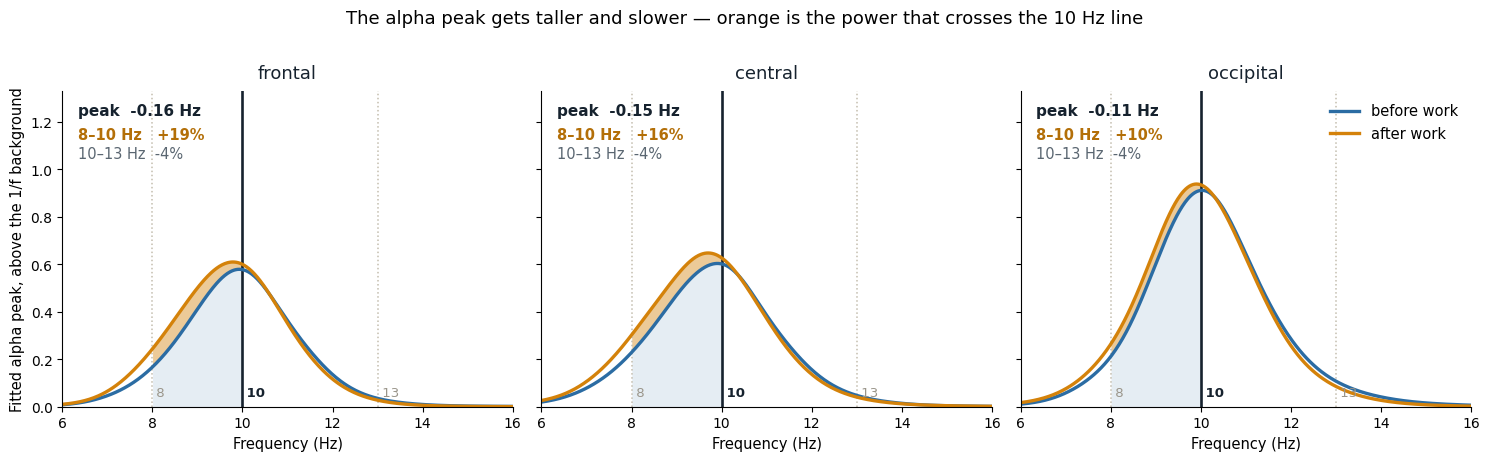

  frontal    n= 572  ความถี่ยอด -0.162 Hz (p=5e-18)   ความสูงยอด +0.0528 (p=5e-07)
  central    n= 576  ความถี่ยอด -0.146 Hz (p=2e-15)   ความสูงยอด +0.0578 (p=8e-11)
  occipital  n= 596  ความถี่ยอด -0.114 Hz (p=2e-13)   ความสูงยอด +0.0244 (p=0.02)


In [5]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import wilcoxon

pk = pd.read_csv('outputs/fooof_peaks_v4.csv'); pk = pk[pk.ap_exponent > 0]
k  = ['subject', 'region']
M  = (pk[pk.condition == 'pre'].set_index(k)
      .join(pk[pk.condition == 'post'].set_index(k), lsuffix='_pre', rsuffix='_post',
            how='inner').reset_index()
      .dropna(subset=['alpha_cf_pre', 'alpha_cf_post', 'alpha_pw_pre', 'alpha_pw_post']))

F  = np.linspace(6, 16, 500)
LO, HI = (F >= 8) & (F < 10), (F >= 10) & (F <= 13)

def peaks(d, s):
    """สร้างยอด alpha ที่ fit ได้ของแต่ละคนขึ้นมาใหม่ แล้วเฉลี่ยทั้งกลุ่ม"""
    cf, pw, bw = (d[f'alpha_{v}_{s}'].values for v in ('cf', 'pw', 'bw'))
    sd = np.clip(bw, 0.5, None) / 2
    return np.exp(-(F[None, :] - cf[:, None])**2 / (2 * sd[:, None]**2)) \
           * np.clip(pw, 0, None)[:, None]

REG = ['frontal', 'central', 'occipital']
CUR = {r: (peaks(M[M.region == r], 'pre').mean(0),
           peaks(M[M.region == r], 'post').mean(0)) for r in REG}
YM  = max(max(a.max(), b.max()) for a, b in CUR.values())

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, rg in zip(axes, REG):
    d, (a, b) = M[M.region == rg], CUR[rg]
    ax.set_ylim(0, YM * 1.42); ax.set_xlim(6, 16)          # ตั้ง ylim ก่อนวางข้อความเสมอ
    for x in (8, 13): ax.axvline(x, color='#c3bdae', lw=1.1, ls=':')
    ax.axvline(10, color='#16222e', lw=1.9)
    ax.fill_between(F, 0, a, where=LO, color='#2b6ca3', alpha=.12, lw=0)
    ax.fill_between(F, a, b, where=LO & (b > a), color='#d4820a', alpha=.42, lw=0)
    ax.plot(F, a, color='#2b6ca3', lw=2.4, label='before work')
    ax.plot(F, b, color='#d4820a', lw=2.4, label='after work')
    for x in (8, 10, 13):
        ax.text(x, YM * .035, f' {x}', ha='left', va='bottom', fontsize=9.5,
                color='#16222e' if x == 10 else '#9a958a',
                fontweight='bold' if x == 10 else 'normal')

    dcf = np.median(d.alpha_cf_post - d.alpha_cf_pre)      # มัธยฐานของผลต่าง ไม่ใช่ผลต่างของมัธยฐาน
    lo  = (b[LO] - a[LO]).sum() / a[LO].sum() * 100
    hi  = (b[HI] - a[HI]).sum() / a[HI].sum() * 100
    ax.text(.035, .96,  f'peak  {dcf:+.2f} Hz', transform=ax.transAxes,
            fontsize=11, fontweight='bold', color='#16222e', va='top')
    ax.text(.035, .885, f'8–10 Hz   {lo:+.0f}%', transform=ax.transAxes,
            fontsize=10.5, color='#B36F08', fontweight='bold', va='top')
    ax.text(.035, .825, f'10–13 Hz  {hi:+.0f}%', transform=ax.transAxes,
            fontsize=10.5, color='#5A6671', va='top')
    ax.set_title(rg, fontsize=13, color='#16222e', pad=9)
    ax.set_xlabel('Frequency (Hz)', fontsize=10.5)
    ax.spines[['top', 'right']].set_visible(False)

axes[0].set_ylabel('Fitted alpha peak, above the 1/f background', fontsize=10.5)
axes[2].legend(frameon=False, fontsize=10.5, loc='upper right')
fig.suptitle('The alpha peak gets taller and slower — orange is the power that crosses '
             'the 10 Hz line', fontsize=13, y=1.015)
plt.tight_layout()
plt.savefig('outputs/nb5b_peak_shift.png', dpi=160, bbox_inches='tight'); plt.show()

for rg in REG:
    d = M[M.region == rg]
    _, p1 = wilcoxon(d.alpha_cf_post - d.alpha_cf_pre)
    _, p2 = wilcoxon(d.alpha_pw_post - d.alpha_pw_pre)
    print(f"  {rg:<11}n={len(d):>4}  "
          f"ความถี่ยอด {np.median(d.alpha_cf_post-d.alpha_cf_pre):+.3f} Hz (p={p1:.1g})   "
          f"ความสูงยอด {np.median(d.alpha_pw_post-d.alpha_pw_pre):+.4f} (p={p2:.1g})")

In [6]:
pd.DataFrame([{'region': rg,
               'cf_pre_median': (d := M[M.region == rg]).alpha_cf_pre.median(),
               'd_cf_median':  (d.alpha_cf_post - d.alpha_cf_pre).median(),
               'd_pw_median':  (d.alpha_pw_post - d.alpha_pw_pre).median(),
               'area_8_10_pct': (CUR[rg][1][LO] - CUR[rg][0][LO]).sum() / CUR[rg][0][LO].sum() * 100,
               'area_10_13_pct': (CUR[rg][1][HI] - CUR[rg][0][HI]).sum() / CUR[rg][0][HI].sum() * 100}
              for rg in REG]).to_csv('outputs/nb5b_peak_shift.csv', index=False)
print(pd.read_csv('outputs/nb5b_peak_shift.csv').round(4).to_string(index=False))

   region  cf_pre_median  d_cf_median  d_pw_median  area_8_10_pct  area_10_13_pct
  frontal         9.9725      -0.1620       0.0528        18.5468         -3.5716
  central         9.8796      -0.1459       0.0578        16.0429         -3.8906
occipital        10.1358      -0.1138       0.0244        10.4340         -3.6294


In [7]:
ages = pd.read_csv('Dataset/participants.tsv', sep='\t').set_index('participant_id')['age']
M['group'] = M.subject.map(ages).apply(
    lambda a: 'Young' if a <= 34 else ('Older' if a >= 51 else 'Middle'))
g = (M[M.group != 'Middle'].groupby(['region', 'group'])
     .apply(lambda d: pd.Series({
         'n': len(d),
         'cf_pre_median': d.alpha_cf_pre.median(),
         'pct_within_0.5Hz_of_10': d.alpha_cf_pre.between(9.5, 10.5).mean() * 100}))
     .reset_index())
g.to_csv('outputs/nb5b_peak_vs_boundary.csv', index=False)
print(g.round(3).to_string(index=False))
print(f"\nยอดของกลุ่มอายุน้อย {g[g.group=='Young'].cf_pre_median.min():.2f}–"
      f"{g[g.group=='Young'].cf_pre_median.max():.2f} Hz  ← ตัวเลขที่ใช้บนสไลด์ 28")

   region group     n  cf_pre_median  pct_within_0.5Hz_of_10
  central Older 213.0          9.558                  33.333
  central Young 201.0         10.111                  42.289
  frontal Older 210.0          9.668                  35.714
  frontal Young 197.0         10.193                  36.548
occipital Older 224.0          9.877                  38.839
occipital Young 202.0         10.315                  42.079

ยอดของกลุ่มอายุน้อย 10.11–10.31 Hz  ← ตัวเลขที่ใช้บนสไลด์ 28


/var/folders/gb/51dj42ln5dlgqczm3vm15bmh0000gn/T/ipykernel_73346/1007262137.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda d: pd.Series({


## การเปลี่ยนแปลงรายบุคคล — ความล้าไม่ได้เท่ากันทุกคน

เปเปอร์ต้นทางรายงานเฉพาะค่าเฉลี่ยของกลุ่ม ส่วนนี้เป็นการต่อยอดของเราเอง
โดยถามว่าภายในกลุ่มอายุเดียวกัน แต่ละคนเปลี่ยนแปลงต่างกันมากน้อยแค่ไหน
และความต่างนั้นเป็นของจริงหรือเป็นความคลาดเคลื่อนของการวัด
(ตัววัดหลัก `low_alpha_corr` · เงื่อนไขหลับตา · n = 608)

### 1 · การกระจายกว้างมากในทุกกลุ่มอายุ

ค่ากลางของ Δ อยู่ที่ **+0.063 ถึง +0.110** แต่ช่วงกลาง 50% ของคน (IQR)
กว้างถึง **0.173 ถึง 0.235** คือประมาณสองเท่าของค่ากลางเอง

**67.8–78.9%** ของคนมีค่าเพิ่มขึ้น ที่เหลือลดลงหรือแทบไม่เปลี่ยน
แปลว่าผลระดับกลุ่มที่พบในส่วนก่อนหน้าเป็นแนวโน้มของคนส่วนใหญ่
ไม่ใช่สิ่งที่เกิดกับทุกคน

### 2 · ช่วงอายุอธิบายความต่างนี้ไม่ได้

| ทดสอบอะไร | วิธี | ผล |
|---|---|---|
| ความกว้างของการกระจายต่างกันไหม | Levene (center=median) | p > 0.18 ทุกช่อง |
| ขนาดการเปลี่ยนแปลงต่างกันไหม | Kruskal–Wallis + Holm | p > 0.29 ทุกช่อง · ε² < 0.01 |

ไม่พบความแตกต่างระหว่าง Young / Middle / Older ทั้งสองแง่
สอดคล้องกับ `age_fatigue_interaction.csv` ใน NB6 ที่ไม่พบปฏิสัมพันธ์
ระหว่างอายุกับความล้าเลย (0 จาก 18 ช่อง) — คนละวิธี แต่ได้คำตอบเดียวกัน

**ความต่างระหว่างบุคคลใหญ่กว่าความต่างระหว่างกลุ่มอายุมาก**

ข้อนี้ต่างจาก NB3 ที่พบว่า Young กับ Older เปลี่ยนต่างกันตอนลืมตา
เพราะ NB3 ใช้ power density ratio ซึ่งยังมีพื้นหลัง 1/f ปนอยู่
ส่วนตรงนี้ใช้ alpha ที่ลบ 1/f ออกแล้ว ความต่างตามอายุที่ NB3 เจอ
จึงอาจมาจากพื้นหลัง 1/f มากกว่าตัว alpha เอง

### 3 · ความกว้างนั้นเป็นของจริง ไม่ใช่สัญญาณรบกวน

การกระจายที่กว้างเพียงอย่างเดียวพิสูจน์ไม่ได้ว่าคนต่างกัน เพราะถึงทุกคน
จะเปลี่ยนเท่ากันเป๊ะ ความคลาดเคลื่อนของการวัดก็ทำให้ได้ฮิสโทแกรมกว้างอยู่ดี
จึงต้องมีการวัดครั้งที่สองมาเทียบ

วิธี split-half — แบ่งการบันทึกของแต่ละคนเป็นท่อนละ 6 วินาที
ท่อนคี่เป็นครึ่ง A ท่อนคู่เป็นครึ่ง B แล้วคำนวณ Δ จากแต่ละครึ่งแยกกัน

| บริเวณ | r ระหว่างสองครึ่ง | reliability (Spearman–Brown) | สองครึ่งไม่ตรงกัน |
|---|---|---|---|
| frontal | 0.723 | **0.839** | 18.8% |
| central | 0.769 | **0.869** | 18.0% |
| occipital | 0.778 | **0.875** | 17.0% |

**reliability 0.84–0.88** แปลว่าการกระจายส่วนใหญ่เป็นความต่างระหว่างคนจริง

และคนที่สองครึ่งไม่ตรงกันคือคนที่ Δ อยู่ใกล้ศูนย์อยู่แล้ว ไม่ใช่คนที่เปลี่ยนเยอะ
— ขนาดของ Δ (ค่าสัมบูรณ์ มัธยฐาน) อยู่ที่ **0.035** ในกลุ่มที่สองครึ่งไม่ตรงกัน
เทียบกับ **0.108** ในกลุ่มที่ลดลงตรงกัน และ **0.164** ในกลุ่มที่เพิ่มขึ้นตรงกัน
คือเล็กกว่าสามถึงห้าเท่า

หมายเหตุ `down_both_halves` (16.0–19.8%) คือสัดส่วนที่ **ลดลงสอดคล้องกัน
ทั้งสองครึ่ง** ไม่ใช่ขอบล่างของคนที่ลดลงจริง เพราะคนที่ไม่เปลี่ยนเลย
ก็มีโอกาสราว 25% ที่ทั้งสองครึ่งจะติดลบพร้อมกันจากความบังเอิญ

### 4 · แต่การตอบสนองขึ้นกับเงื่อนไข ไม่ใช่ลักษณะประจำตัว

Δ ของคนเดียวกันตอนลืมตากับหลับตาสอดคล้องกันแค่ **r ≈ 0.21–0.29**
(95% CI [0.13, 0.36] · permutation p = 0.0005 ทุกบริเวณ)

ค่าที่ต่ำนี้อาจเกิดจากการที่เงื่อนไขลืมตาวัดได้ไม่แม่น ซึ่งจะดึงค่าสหสัมพันธ์
ลงเองโดยอัตโนมัติ (attenuation) จึงทดสอบโดยรัน split-half กับเงื่อนไขลืมตาด้วย

| | split-half reliability |
|---|---|
| หลับตา | 0.839–0.875 |
| **ลืมตา** | **0.793–0.833** |

ลืมตาวัดได้แม่นพอ ๆ กับหลับตา และเมื่อแก้ค่าตามสูตร
`r_true = r / √(rel_EC × rel_EO)` ได้ **r ≈ 0.25–0.35**
(CI สูงสุด 0.44) ยังต่ำอยู่

คำอธิบายเรื่องการวัดไม่แม่นจึงถูกตัดออกด้วยข้อมูล นอกจากนี้ ลืมตากับหลับตา
ของแต่ละคนถูกบันทึกในเซสชันเดียวกัน ถ้าความคลาดเคลื่อนจากหมวกที่ขยับหรือ
เจลที่แห้งเป็นตัวหลัก มันจะทำให้สองเงื่อนไข **ตรงกันมากขึ้น ไม่ใช่น้อยลง**

ตีความว่าการตอบสนองต่อความล้าไม่ใช่ลักษณะที่ติดตัวและเห็นเหมือนกันทุกเงื่อนไข
ซึ่งมีนัยเชิงปฏิบัติว่า เครื่องวัดความล้าจาก EEG ต้องกำหนดเงื่อนไขการวัด
ให้ตายตัว จะสอบเทียบตอนหลับตาแล้วเอาไปใช้ตอนลืมตาไม่ได้

### ข้อจำกัด

- **split-half เป็นขอบบนของ reliability** เพราะเห็นเฉพาะความคลาดเคลื่อน
  ภายในไฟล์เดียว ยังมองไม่เห็นการเปลี่ยนของ impedance หรือหมวกที่ขยับ
  ระหว่างการวัดก่อนกับหลัง
- **ทั้งหมดนี้วัด "EEG เปลี่ยนไปเท่าไร" ไม่ใช่ "ล้าแค่ไหน"**
  ชุดข้อมูลไม่มีคะแนนความล้าที่ผู้เข้าร่วมประเมินเอง หรือคะแนนความสามารถ
  รายบุคคล มาใช้เป็นเกณฑ์ จึงบอกไม่ได้ว่าใครล้ามากกว่าใคร
- การแก้ attenuation ใช้ reliability จาก split-half ซึ่งเป็นขอบบน ค่า r
  ที่แก้แล้วจึงอาจยังต่ำกว่าความจริง แต่ความคลาดเคลื่อนที่ split-half
  มองไม่เห็น (impedance หรือหมวกที่เปลี่ยนระหว่างก่อนกับหลัง) เกิดร่วมกัน
  ทั้งตอนลืมตาและหลับตา เพราะบันทึกต่อเนื่องกัน ความคลาดเคลื่อนส่วนนี้
  จึงน่าจะดัน r ขึ้นมากกว่ากดลง

### ไฟล์ผลลัพธ์

| ไฟล์ | เนื้อหา |
|---|---|
| `outputs/individual_delta_low_alpha_corr.csv` | median · IQR · %เพิ่มขึ้น แยกตามอายุและบริเวณ |
| `outputs/age_group_delta_low_alpha_corr.csv` | Kruskal–Wallis เทียบกลุ่มอายุ |
| `outputs/consistency_tested_low_alpha_corr.csv` | r(EO, EC) พร้อม CI และ permutation test |
| `outputs/splithalf_features_v2.csv` | ฟีเจอร์รายครึ่ง — หลับตา |
| `outputs/splithalf_features_EO.csv` | ฟีเจอร์รายครึ่ง — ลืมตา |
| `outputs/splithalf_reliability_v2_low_alpha_corr.csv` | reliability หลับตา |
| `outputs/splithalf_reliability_EO_low_alpha_corr.csv` | reliability ลืมตา |
| `outputs/attenuation_corrected_low_alpha_corr.csv` | r หลังแก้ attenuation |
| `outputs/individual_delta_low_alpha_corr.png` | ฮิสโทแกรมการกระจาย อายุ × บริเวณ |
| `outputs/individual_delta_bycat.png` | ฮิสโทแกรมแยกสีสามกลุ่ม — ใช้ในสไลด์ |